# Frequentist analysis of the raw asymmetry in $B^\pm\to K^\pm K^+K^-$

Single notebook of the frequentist part of the report (Secs. *Frequentist Analysis*, *Systematic Uncertainties*, *Dalitz*):

1. data, preselection, invariant mass;
2. extended unbinned maximum-likelihood fit (sidebands, separate fits, simultaneous fit with $A$ as a parameter), goodness of fit;
3. profile likelihood, Minos intervals, Wilks test of $A=0$, bootstrap coverage;
4. stability scans (fit window, signal region, PID cuts);
5. systematic study common to the Bayesian analysis (13 variants), charm vetoes, fine PID scan;
6. Dalitz plots, charm vetoes and the local asymmetry.

The functions are in `lhcb_freq.py`. The data directory is the environment variable `LHCB_DATA_DIR` (default `../../opendata-project/Data`).
Outputs: `results/freq_systematics.json`, `results/freq_pid_scan.json`, `results/frequentist_wilks_coverage.pdf`.
The validation on toy MC (Sec. *Validation*) is in `freq_validation.py` (`run_validation.sh`). Full run: ~1 h.

In [ ]:
%load_ext autoreload
%autoreload 2

import os, json, warnings
from pathlib import Path
from dataclasses import replace

import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import CenteredNorm
import scipy.stats

warnings.filterwarnings("ignore", category=RuntimeWarning)
import lhcb_freq as lf   # functions + settings live in lhcb_freq.py

In [ ]:
# All the settings in one place (fit window, signal region, preselection cuts, n. of exponentials, limits, ...)
_DATA = Path(os.environ.get("LHCB_DATA_DIR", "../../opendata-project/Data"))
cfg = lf.Config(
    data_dir=_DATA,
    sim_file=_DATA / "PhaseSpaceSimulation.root",
)
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
cfg

## Simulation Data

In [3]:
df_sim = lf.load_tree(cfg.sim_file, cfg.sim_tree)
print(df_sim.columns.tolist())
df_sim.head()

['B_FlightDistance', 'B_VertexChi2', 'H1_PX', 'H1_PY', 'H1_PZ', 'H1_ProbK', 'H1_ProbPi', 'H1_Charge', 'H1_IPChi2', 'H1_isMuon', 'H2_PX', 'H2_PY', 'H2_PZ', 'H2_ProbK', 'H2_ProbPi', 'H2_Charge', 'H2_IPChi2', 'H2_isMuon', 'H3_PX', 'H3_PY', 'H3_PZ', 'H3_ProbK', 'H3_ProbPi', 'H3_Charge', 'H3_IPChi2', 'H3_isMuon']


,B_FlightDistance,B_VertexChi2,H1_PX,H1_PY,H1_PZ,H1_ProbK,H1_ProbPi,H1_Charge,H1_IPChi2,H1_isMuon,...,H2_IPChi2,H2_isMuon,H3_PX,H3_PY,H3_PZ,H3_ProbK,H3_ProbPi,H3_Charge,H3_IPChi2,H3_isMuon
0,0.0,1.0,3551.84,1636.96,23904.14,1.0,0.0,-1,1.0,0,...,1.0,0,36100.40,16546.83,295600.61,1.0,0.0,-1,1.0,0
1,0.0,1.0,-2525.98,-5284.05,35822.00,1.0,0.0,1,1.0,0,...,1.0,0,-8648.32,-16617.56,98535.13,1.0,0.0,-1,1.0,0
2,0.0,1.0,-700.67,1299.73,8127.76,1.0,0.0,-1,1.0,0,...,1.0,0,-13483.34,10860.77,79787.59,1.0,0.0,1,1.0,0
3,0.0,1.0,3364.63,1397.30,222815.29,1.0,0.0,1,1.0,0,...,1.0,0,1925.16,-551.12,40420.96,1.0,0.0,1,1.0,0
4,0.0,1.0,-581.66,-1305.24,22249.59,1.0,0.0,-1,1.0,0,...,1.0,0,-2820.04,-8305.43,250130.00,1.0,0.0,-1,1.0,0


### Data exploration

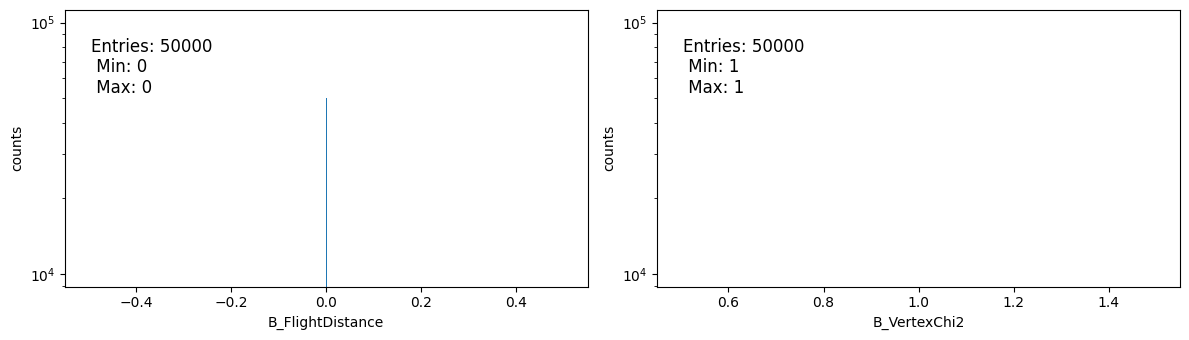

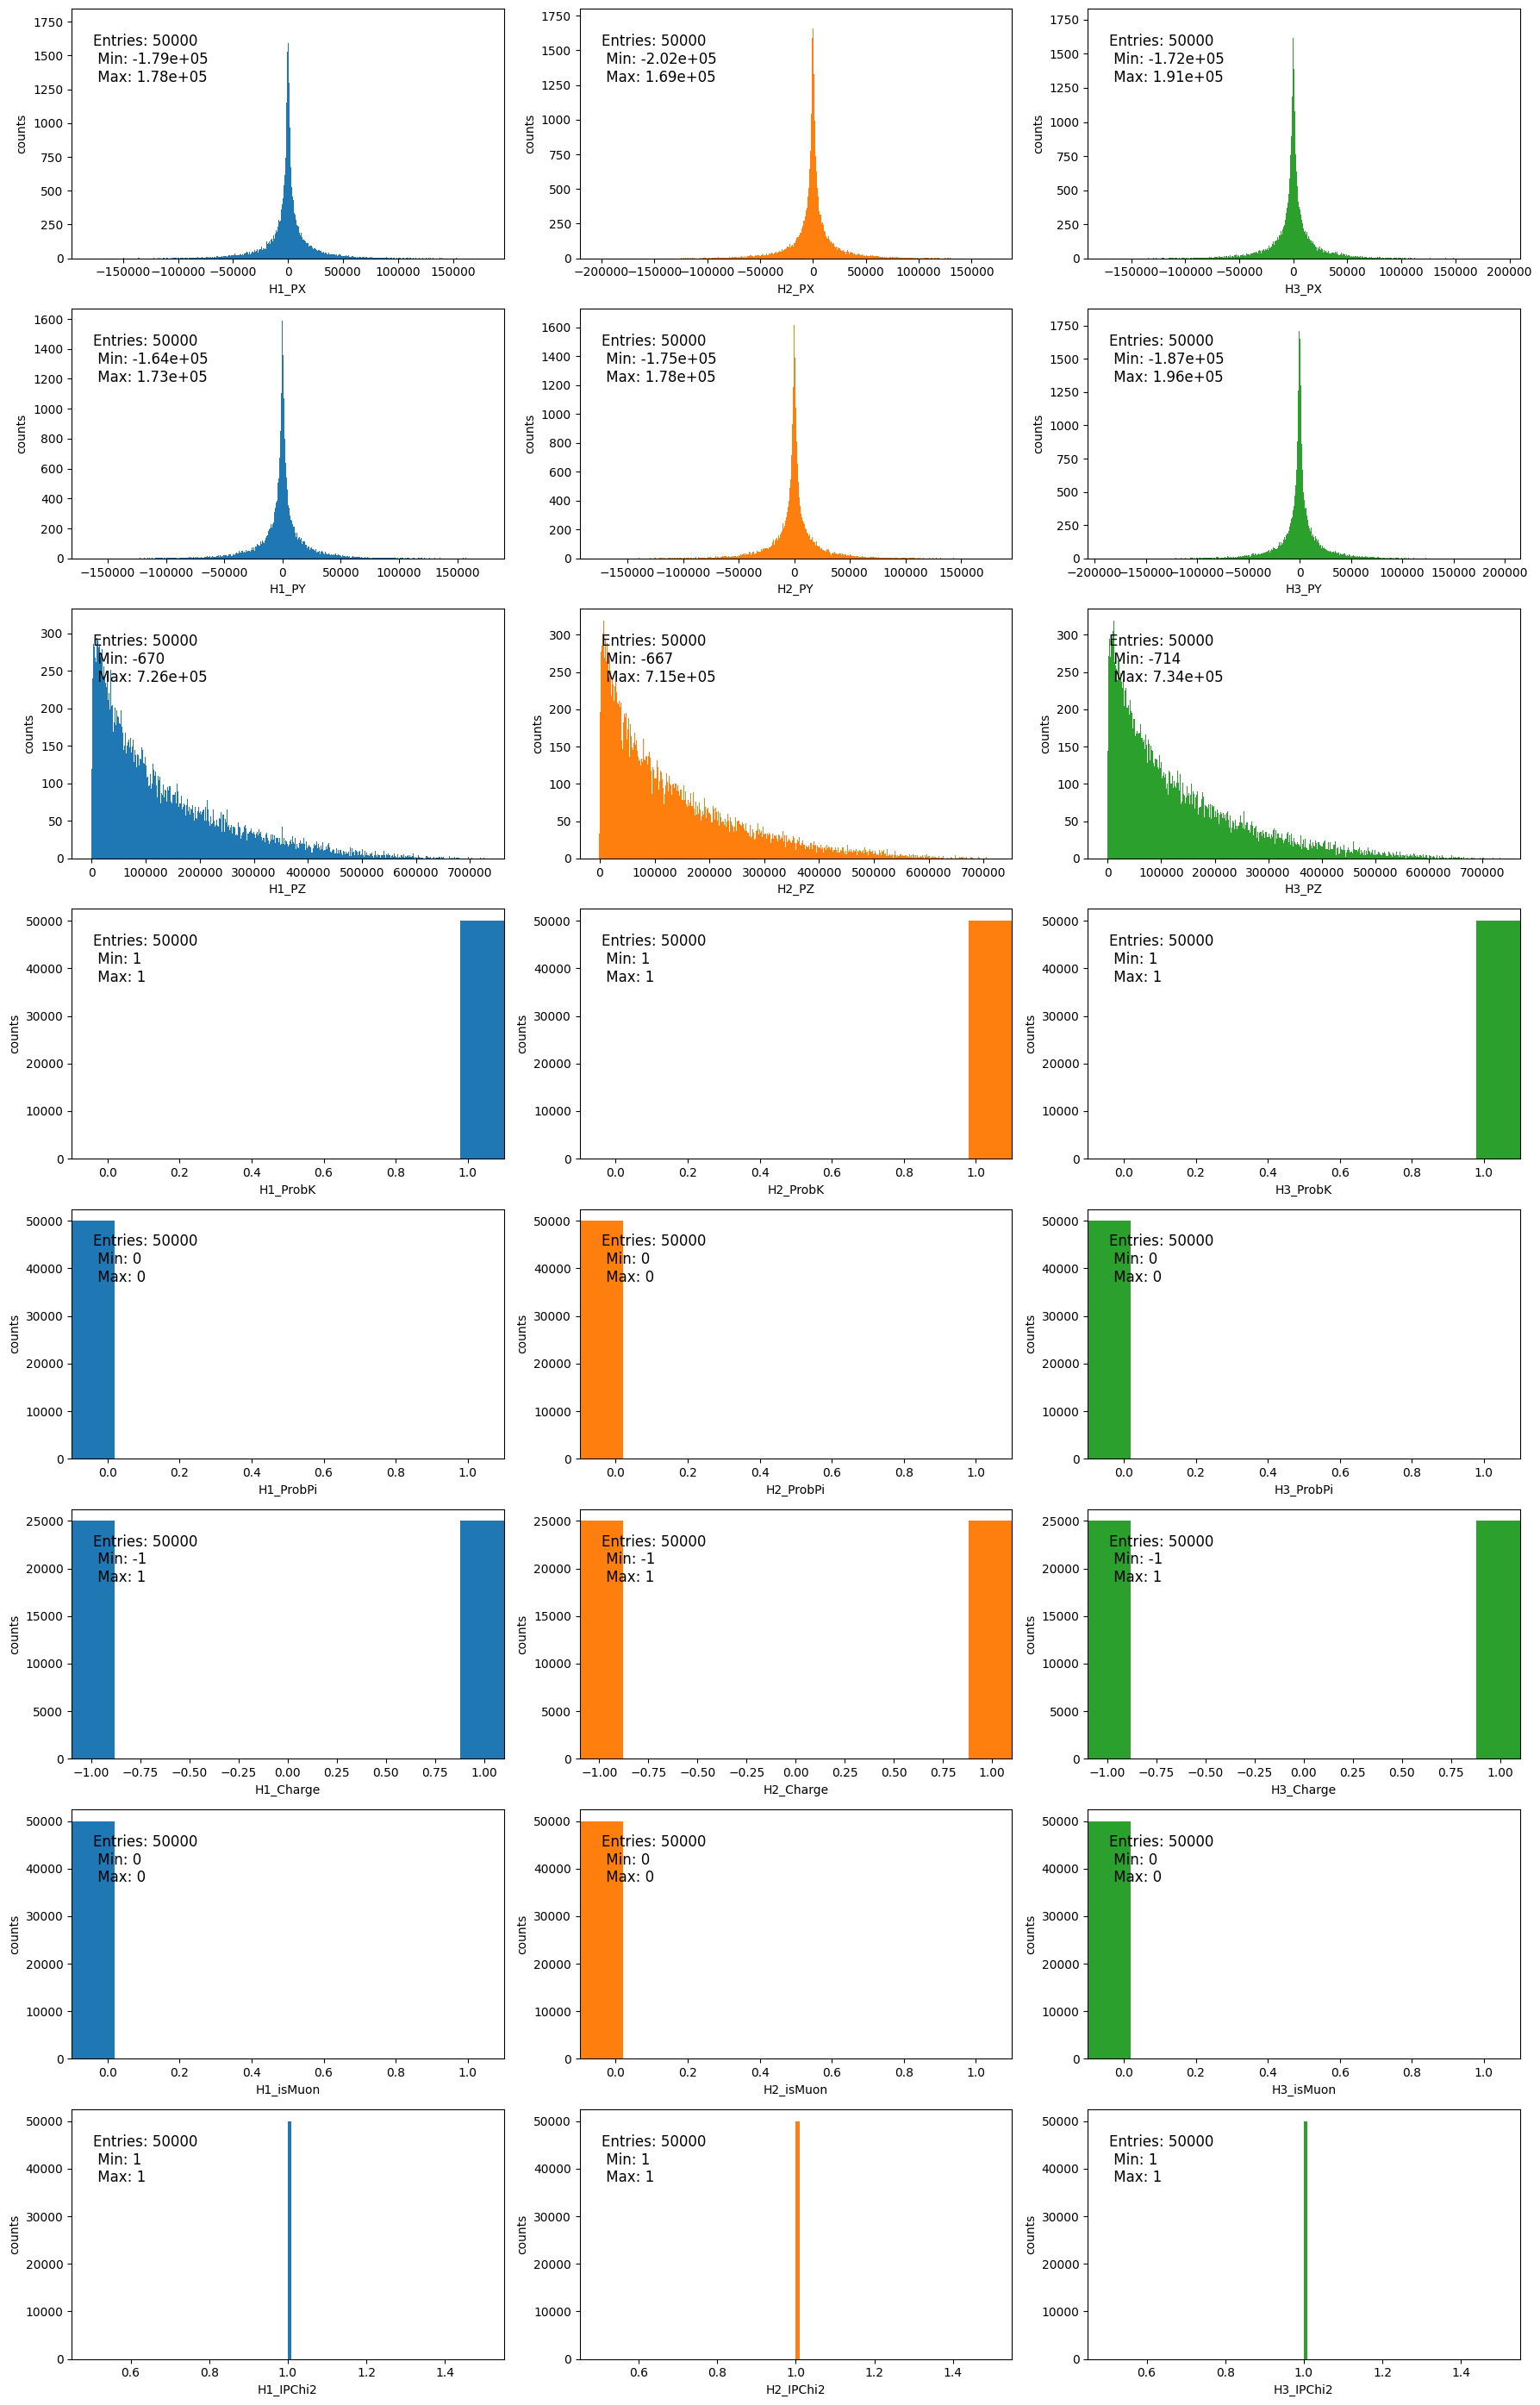

In [4]:
figs = lf.plot_all_features(df_sim, lf.GLOBAL_FEATURES, lf.PRODUCT_FEATURES + lf.EXTRA_PRODUCT_FEATURES,
                            lf.PLOT_SETTINGS["sim"], cfg.n_products)

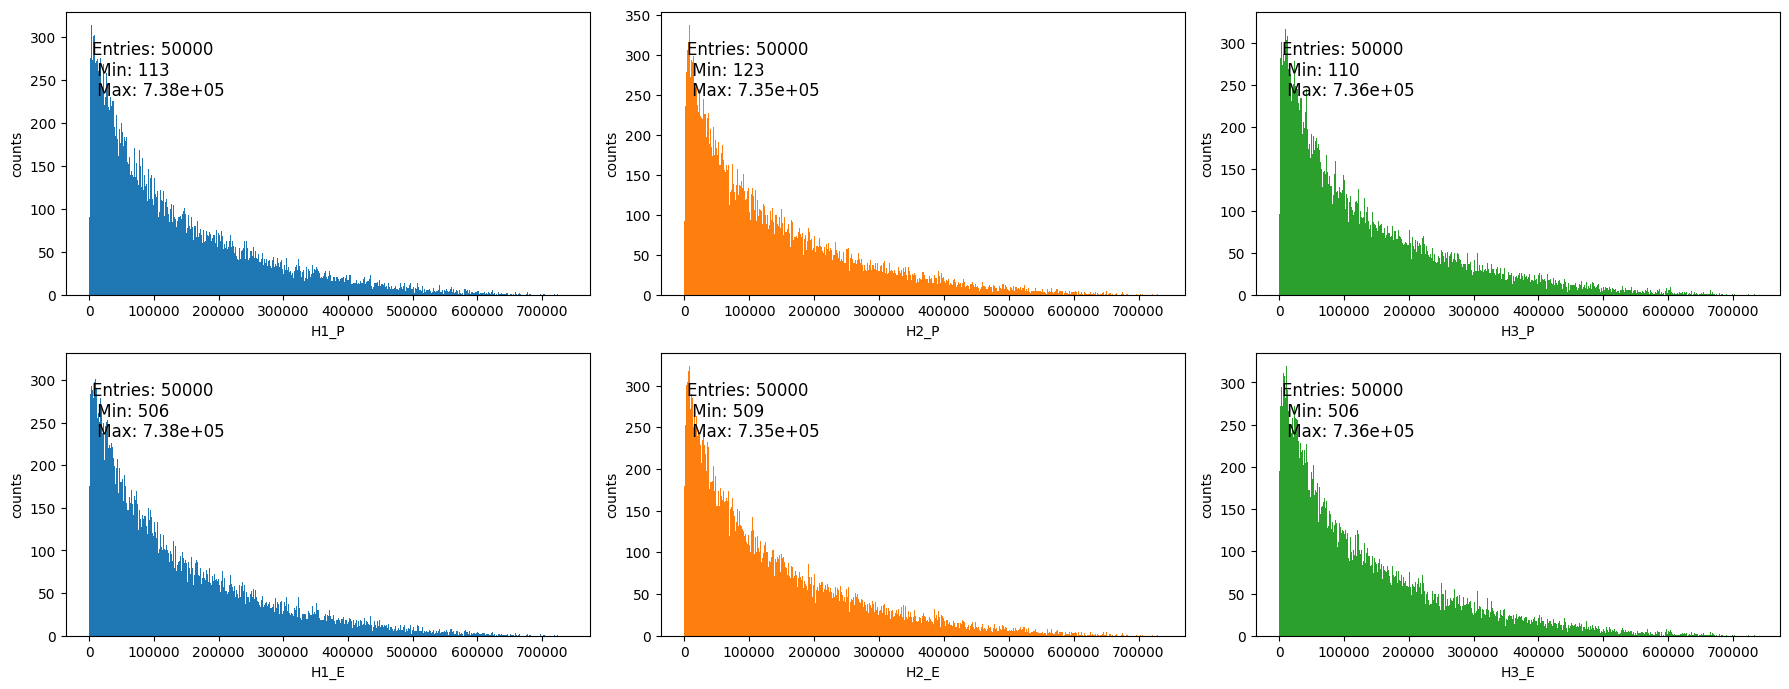

In [5]:
# New features: momentum magnitude and energy of each product
lf.add_kinematics(df_sim, cfg)
figs = lf.plot_all_features(df_sim, product_features=["P", "E"], settings=lf.PLOT_SETTINGS["sim"], n_products=cfg.n_products)

### Compute Invariant Mass

In [6]:
lf.add_B_variables(df_sim, cfg)      # adds B_Mass and B_Charge
df_sim[["B_Mass", "B_Charge"]].describe()

,B_Mass,B_Charge
count,50000.000000,50000.00000
mean,5267.883223,0.00000
std,80.964681,1.00001
min,2909.905221,-1.00000
25%,5279.241654,-1.00000
50%,5279.248254,0.00000
75%,5279.253599,1.00000
max,5279.279077,1.00000


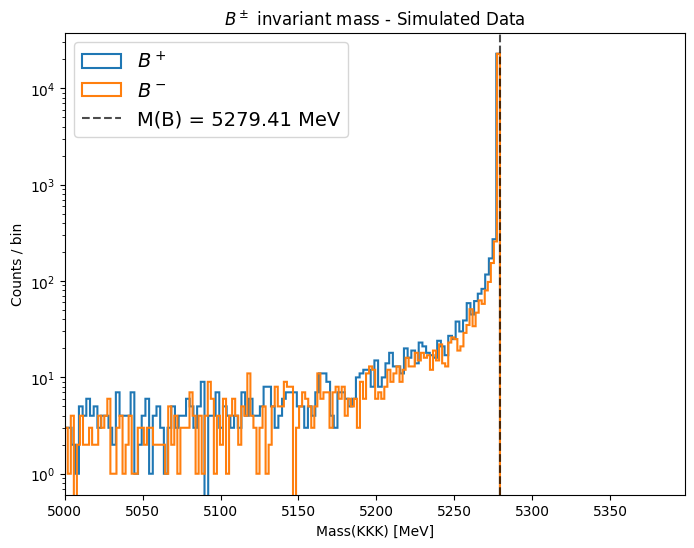

In [7]:
lf.plot_mass_by_charge(df_sim, cfg, bins=1000, logy=True, xlim=(5000, None),
                       title=r"$B^\pm$ invariant mass - Simulated Data");

max |m_vector - m_numpy| = 2.7284841053187847e-12 MeV


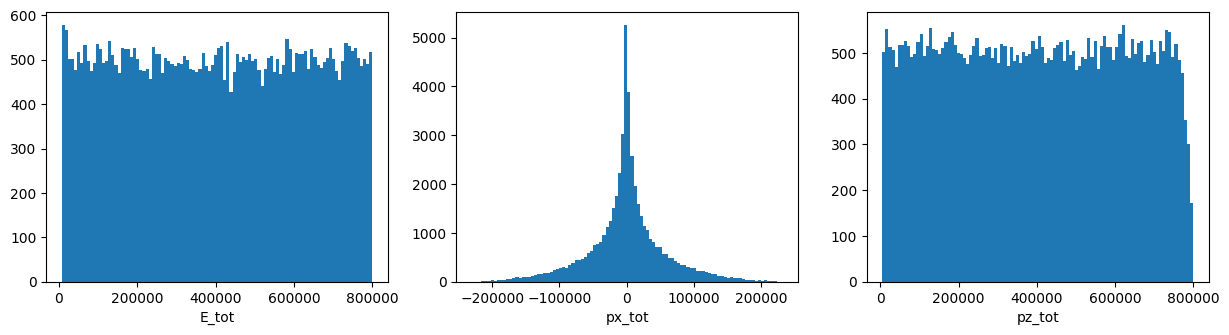

In [8]:
# Independent cross-check of the `vector` result with plain numpy (energy/momentum conservation, m^2 = E^2 - p^2)
E_tot = sum(np.sqrt(sum(df_sim[f"H{i}_{c}"]**2 for c in ("PX", "PY", "PZ")) + cfg.m_K**2) for i in cfg.particles)
p_tot = {c: sum(df_sim[f"H{i}_{c}"] for i in cfg.particles) for c in ("PX", "PY", "PZ")}
m_manual = np.sqrt(E_tot**2 - sum(v**2 for v in p_tot.values()))
print("max |m_vector - m_numpy| =", np.abs(m_manual - df_sim["B_Mass"]).max(), "MeV")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (name, v) in zip(axes, {"E_tot": E_tot, "px_tot": p_tot["PX"], "pz_tot": p_tot["PZ"]}.items()):
    ax.hist(v, bins=100)
    ax.set_xlabel(name)

# Real Data

#### Load Data

In [9]:
all_data = lf.load_data(cfg)
print("total events read:", len(all_data))
all_data.head()

total events read: 8556118


,B_FlightDistance,B_VertexChi2,H1_PX,H1_PY,H1_PZ,H1_ProbK,H1_ProbPi,H1_Charge,H1_IPChi2,H1_isMuon,...,H2_isMuon,H3_PX,H3_PY,H3_PZ,H3_ProbK,H3_ProbPi,H3_Charge,H3_IPChi2,H3_isMuon,magnet
0,25.301004,1.497280,375.284205,831.308481,51820.233718,0.038616,0.888755,-1,212.776776,0,...,0,-208.210960,-2586.359121,105848.271681,0.193004,0.138845,1,61.157888,1,down
1,94.690700,1.383338,-4985.130785,5853.750057,326157.454706,0.073556,0.039064,-1,373.815885,1,...,1,-175.018535,1325.178792,87681.561846,0.080397,0.758603,1,185.092016,0,down
2,8.284490,5.187101,-1265.456544,2330.050788,90762.658032,0.030095,0.636693,1,53.187855,0,...,0,-1383.996490,-71.081104,85574.929582,0.750751,0.399602,-1,1.481413,0,down
3,5.590769,7.129099,-720.797259,3413.790588,86793.058768,0.211414,0.350969,-1,6.232666,0,...,0,398.775944,-1134.914464,14653.316611,0.005698,0.964705,1,468.174038,0,down
4,3.013242,10.988701,397.754571,1791.373059,40040.364159,0.005697,0.933102,-1,3.137287,0,...,0,477.148467,2113.439057,24462.076980,0.002979,0.918983,1,60.530372,0,down


#### Data Exploration

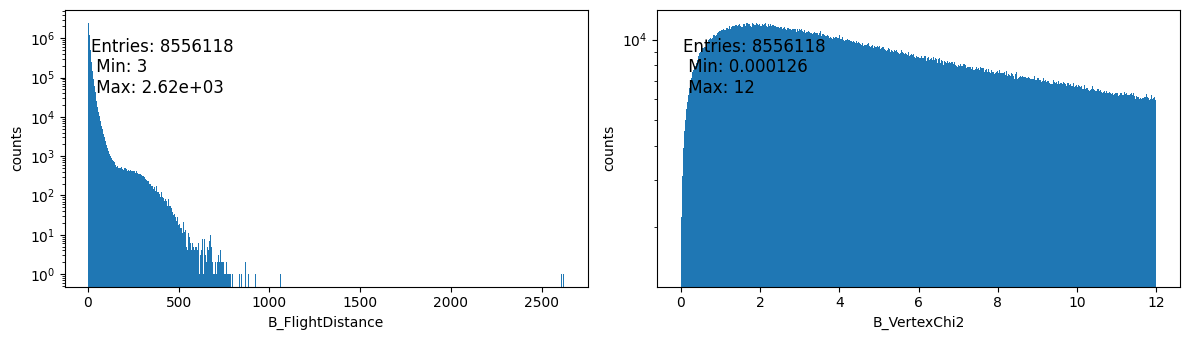

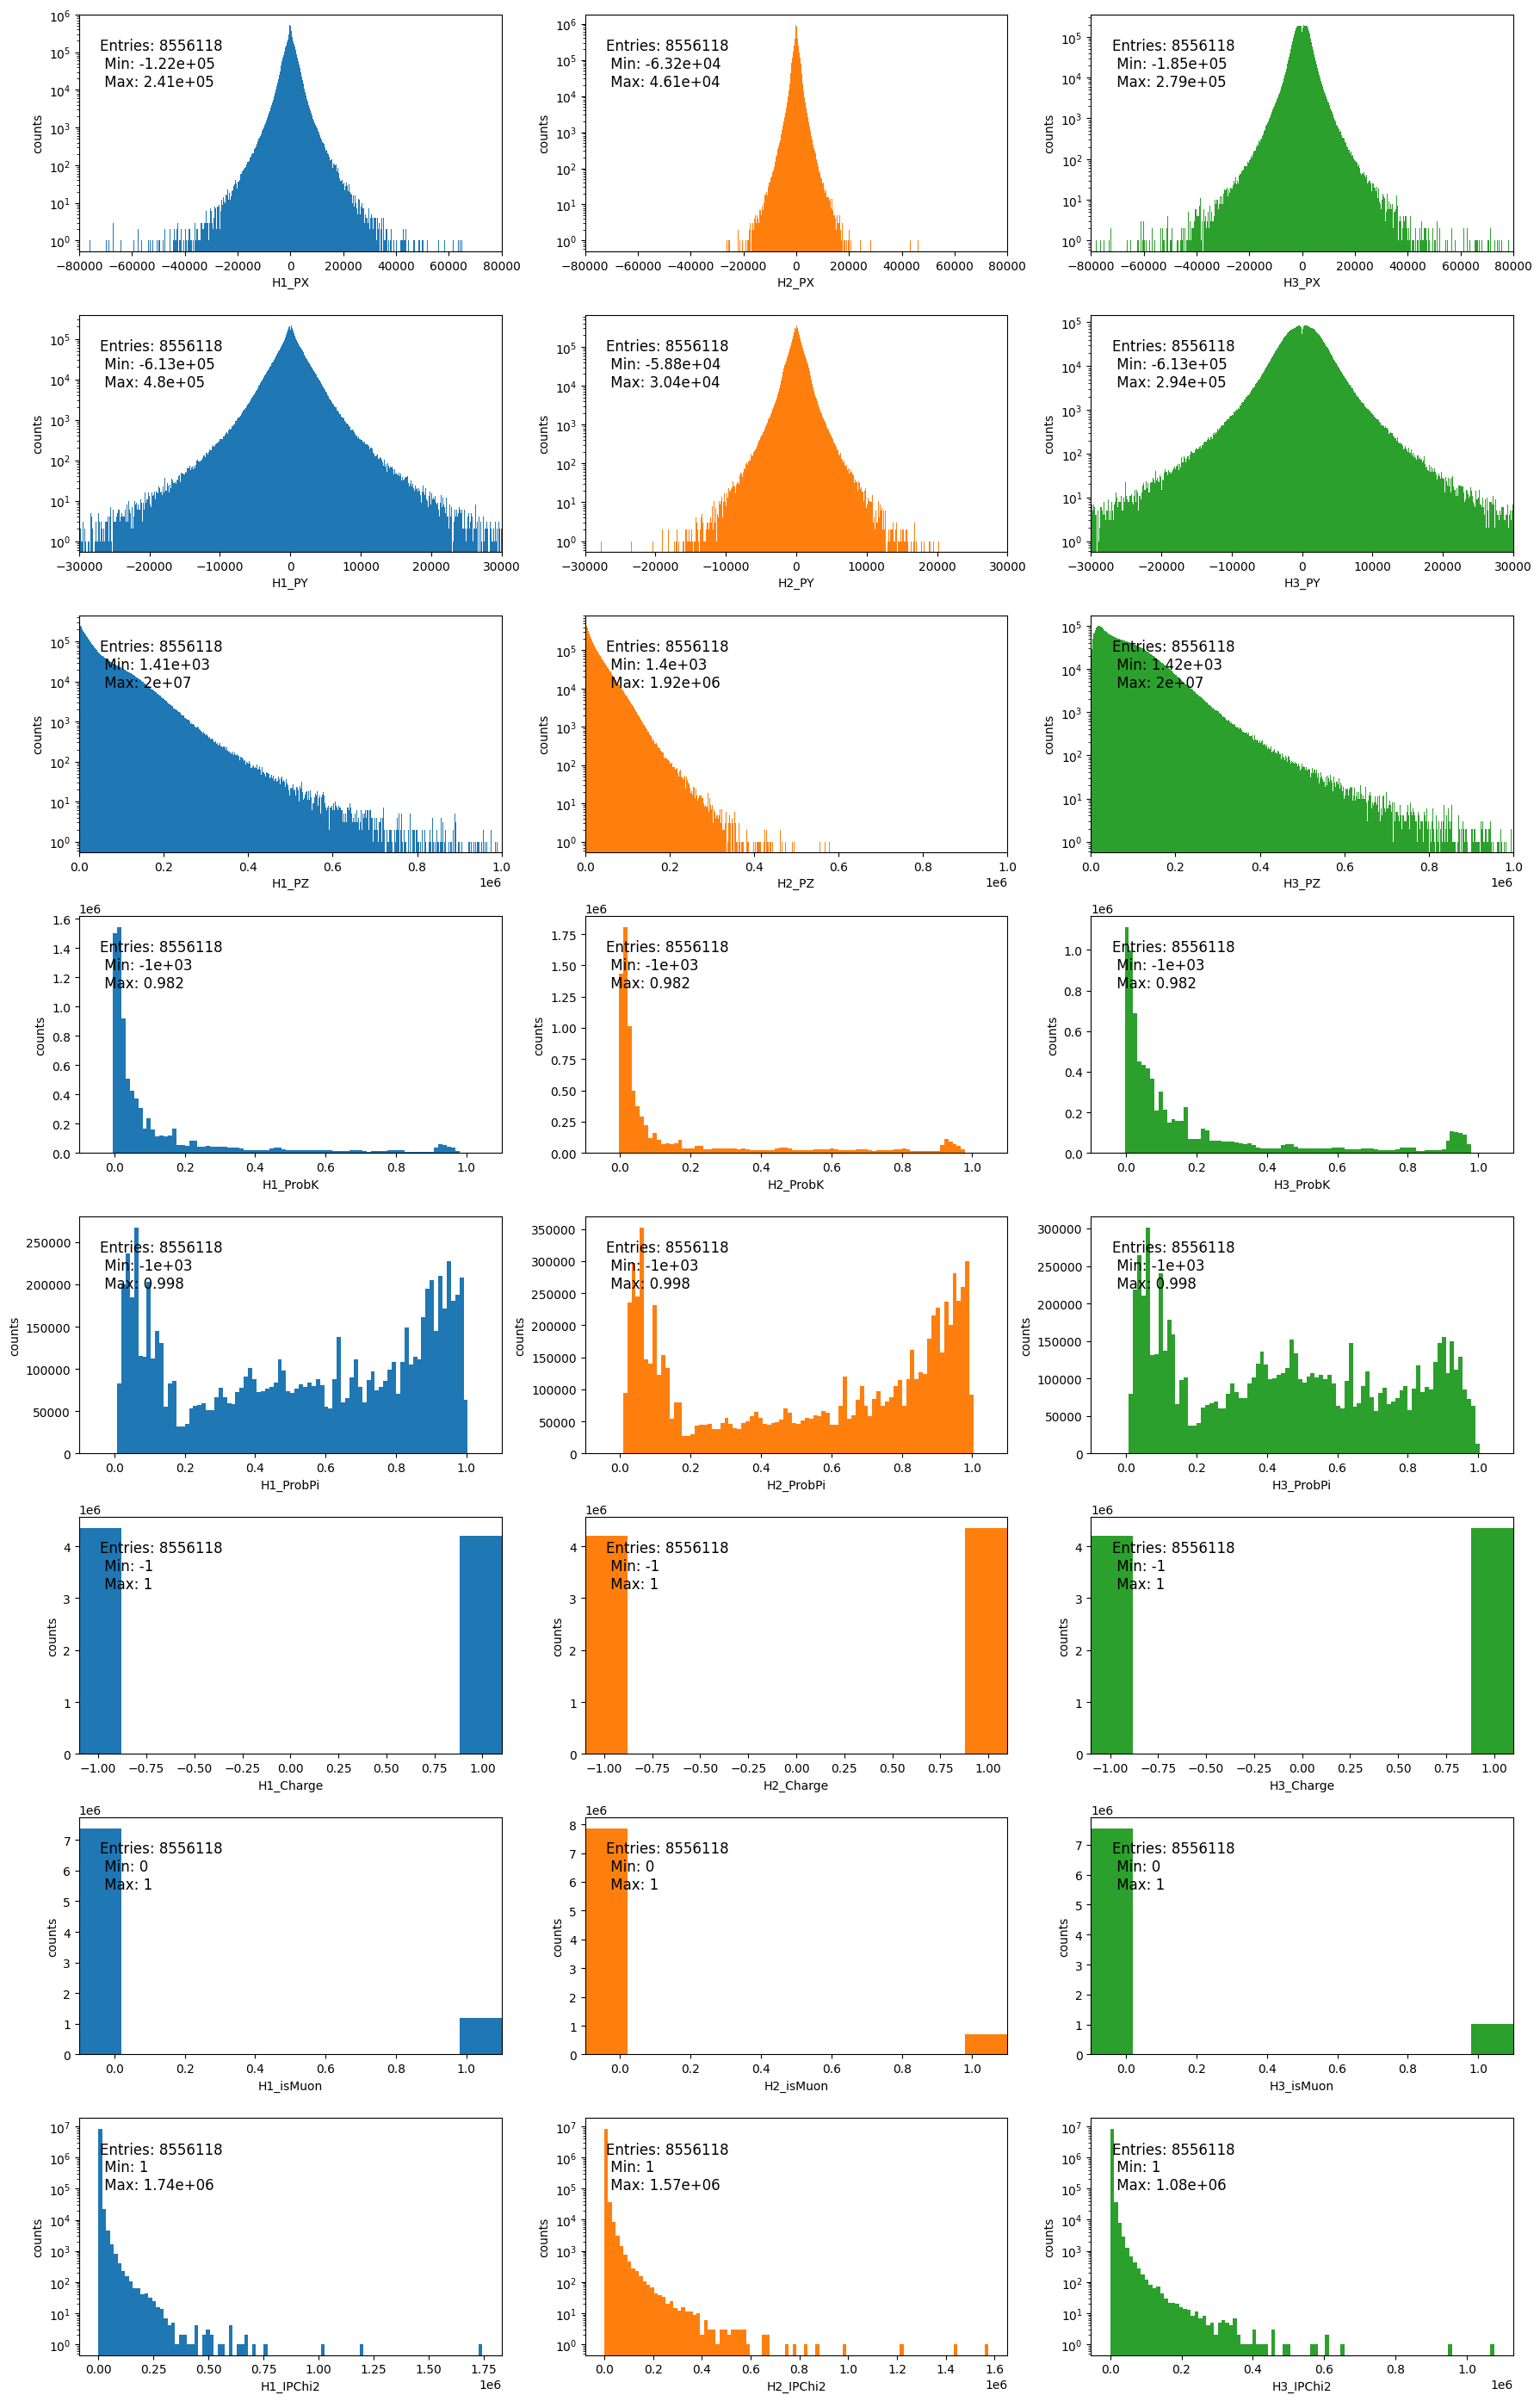

In [10]:
figs = lf.plot_all_features(all_data, lf.GLOBAL_FEATURES, lf.PRODUCT_FEATURES + lf.EXTRA_PRODUCT_FEATURES,
                            lf.PLOT_SETTINGS["raw"], cfg.n_products)

In [11]:
# keep only the columns needed by the analysis
data = all_data[cfg.columns].copy()
del all_data
print(data.columns.tolist())

['H1_PX', 'H1_PY', 'H1_PZ', 'H1_ProbK', 'H1_ProbPi', 'H1_Charge', 'H1_isMuon', 'H2_PX', 'H2_PY', 'H2_PZ', 'H2_ProbK', 'H2_ProbPi', 'H2_Charge', 'H2_isMuon', 'H3_PX', 'H3_PY', 'H3_PZ', 'H3_ProbK', 'H3_ProbPi', 'H3_Charge', 'H3_isMuon', 'magnet']


### Preselection (B -> KKK)

preselection efficiency: 0.28%


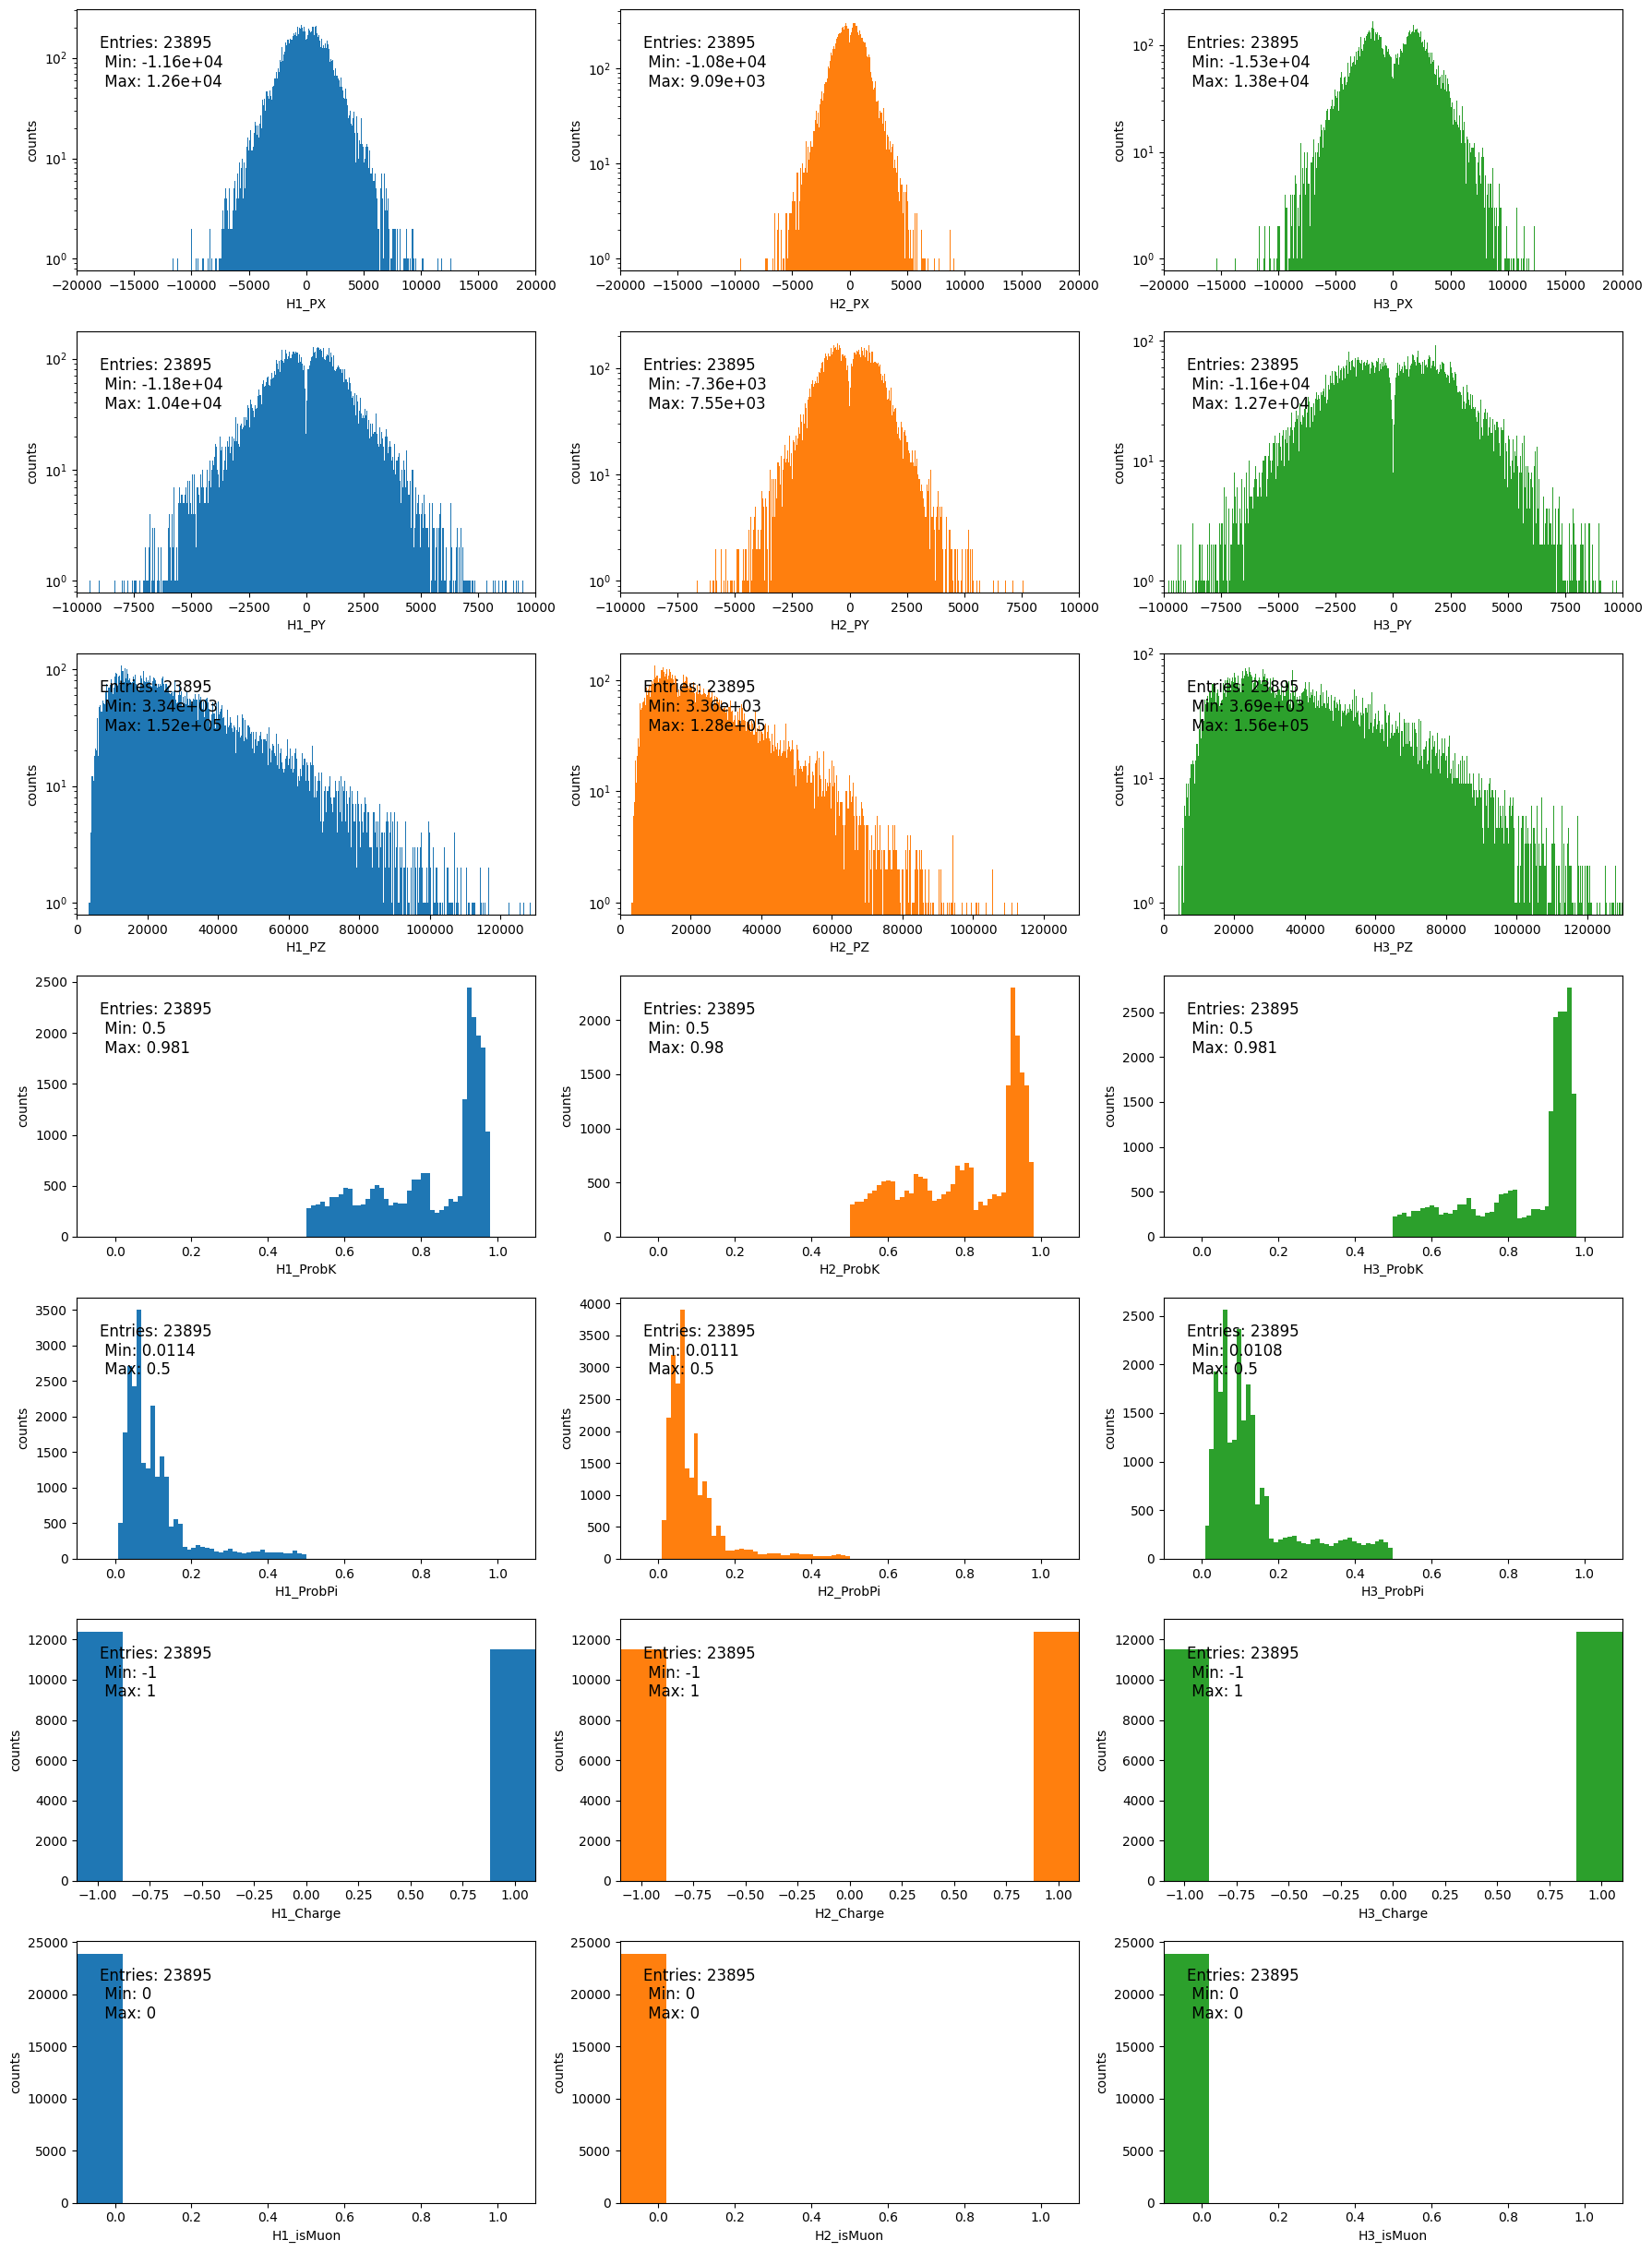

In [12]:
presel_kaon = lf.kaon_preselection(data, cfg)     # boolean mask: 3 kaons, no pions, no muons
print(f"preselection efficiency: {presel_kaon.mean():.2%}")
figs = lf.plot_all_features(data[presel_kaon], product_features=lf.PRODUCT_FEATURES,
                            settings=lf.PLOT_SETTINGS["presel"], n_products=cfg.n_products)

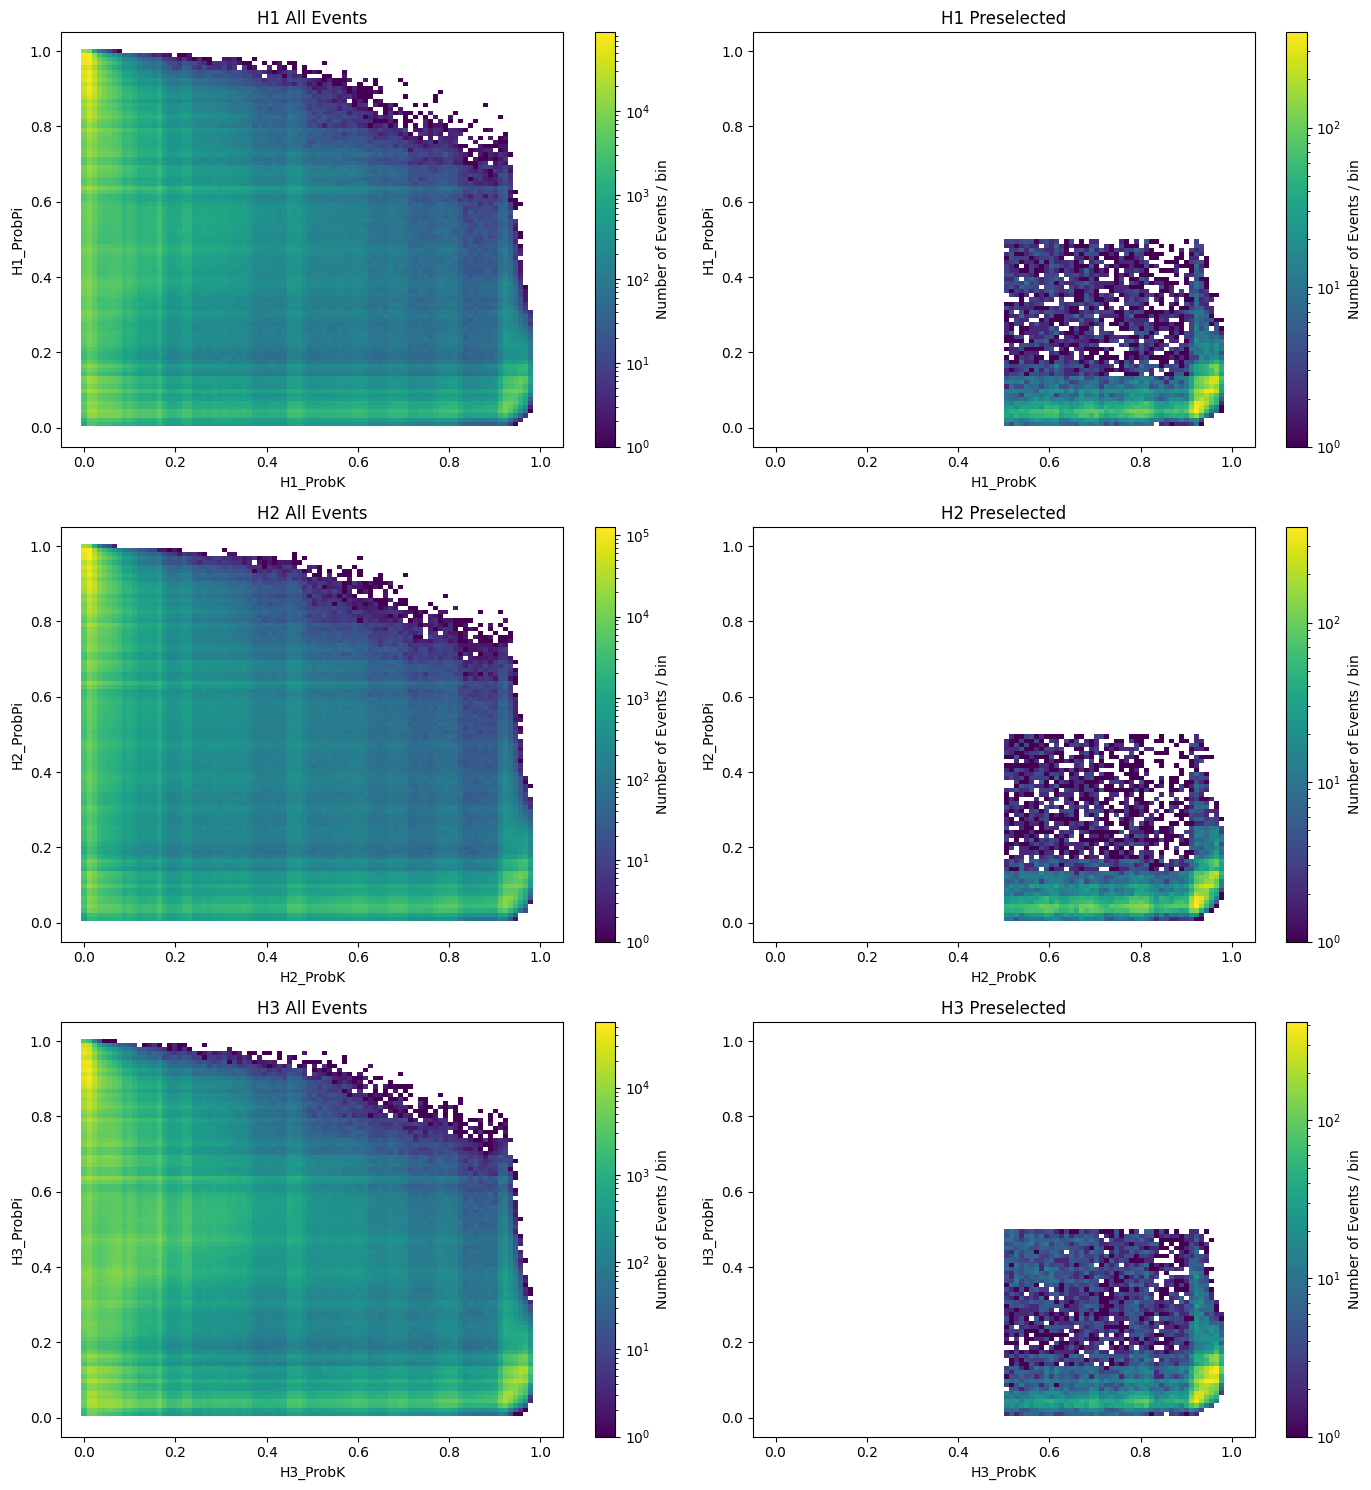

In [13]:
# 2D plot of ProbK vs ProbPi, before / after the preselection
lf.plot_pid_2d(data, data[presel_kaon], cfg);

### Compute Invariant Mass

In [14]:
# Samples with PID cuts looser than every variant of the scans: the scans re-apply the cuts of each variant,
# so they must start from a sample not yet preselected with the nominal cuts (0.5).
data_loose = data[lf.kaon_preselection(data, replace(cfg, prob_k_min=0.4, prob_pi_max=0.6))].reset_index(drop=True)
lf.add_B_variables(data_loose, cfg)         # ProbK > 0.4, ProbPi < 0.6: systematic study and scan of the cuts
data_scan = data[lf.kaon_preselection(data, replace(cfg, prob_k_min=0.3, prob_pi_max=0.7))].reset_index(drop=True)
lf.add_B_variables(data_scan, cfg)          # ProbK > 0.3, ProbPi < 0.7: fine scan of the PID cuts

data = data[presel_kaon].reset_index(drop=True)
lf.add_B_variables(data, cfg)        # B_Mass and B_Charge (= sum of the product charges)
lf.check_charges(data, cfg)          # all charges must be +-1
print(data["B_Charge"].value_counts())

H1_Charge: [-1  1]
H2_Charge: [-1  1]
H3_Charge: [-1  1]
B_Charge
 1    12390
-1    11505
Name: count, dtype: int64


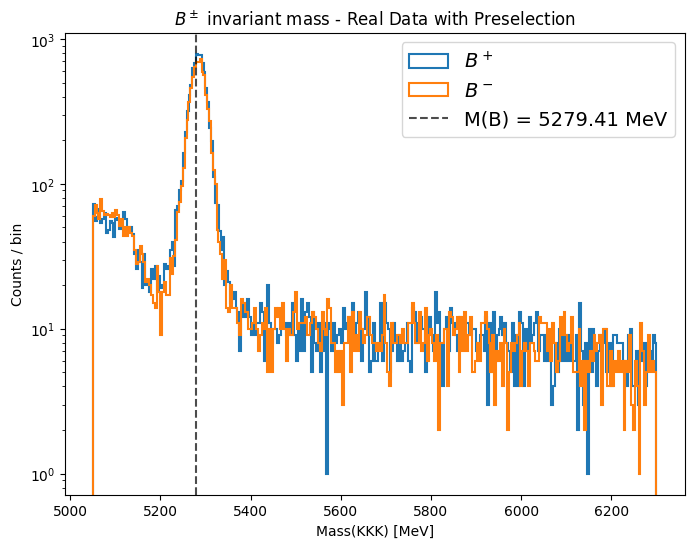

In [15]:
lf.plot_mass_by_charge(data, cfg, bins=300, logy=True, title=r"$B^\pm$ invariant mass - Real Data with Preselection");

events in fit window [5100.0, 5600.0] MeV: 19731
  B+ : 10292   B- : 9439  -->  raw A_CP = -0.043231 ± 0.007112
  magnet down: 11636   magnet up: 8095


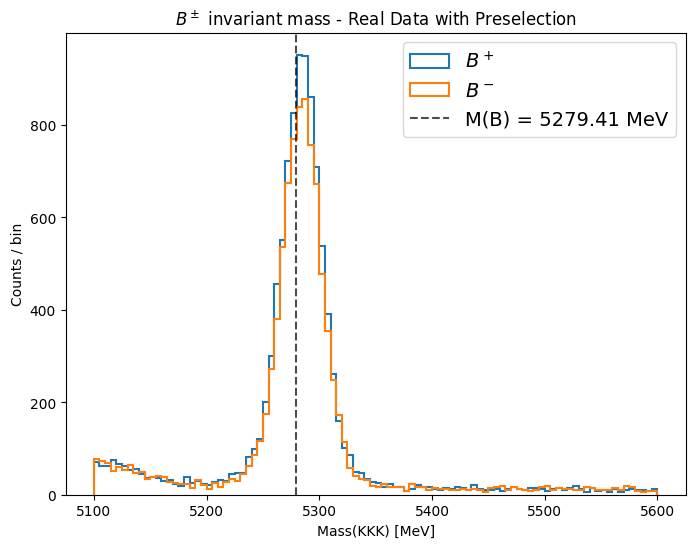

In [16]:
# cut the data in the fit window and split in B+ / B-
data_window = lf.select_window(data, cfg.fit_window)
samples = lf.split_by_charge(data_window, col='B_Mass')       # {'pos': B+ masses, 'neg': B- masses}

lf.plot_mass_by_charge(data_window, cfg, bins=100, bin_range=cfg.fit_window,
                       title=r"$B^\pm$ invariant mass - Real Data with Preselection")
lf.print_event_summary(data_window, cfg)

## Frequentist fit

Conventions (see `lhcb_freq.py`): the model is *extended* (signal yield and background yield are fit parameters),
signal = Gaussian, background = 1 or 2 exponentials (`cfg.n_exp`), both normalised in `cfg.fit_window`.
`A_CP = (N(B-) - N(B+)) / (N(B-) + N(B+))`.

### Sideband

Events in sideband (B+ / B-): 1530 / 1516 | total: 19731
Sideband pos
lam1       -> 0.025433 ± 0.004433
lam2       -> 0.001827 ± 0.000467
f_bkgs     -> 0.276517 ± 0.047763
Sideband neg
lam1       -> 0.024230 ± 0.003569
lam2       -> 0.001090 ± 0.000504
f_bkgs     -> 0.326013 ± 0.043662


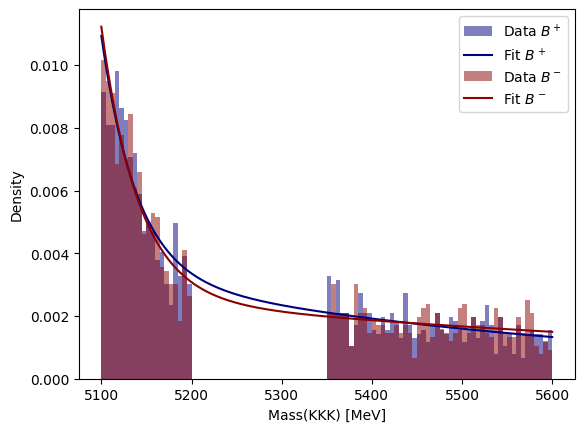

In [17]:
# Sideband = fit window without the signal region
sb_samples = {s: lf.select_sideband(m, cfg) for s, m in samples.items()}
print("Events in sideband (B+ / B-):", len(sb_samples["pos"]), "/", len(sb_samples["neg"]), "| total:", len(data_window))

sb_fits = {s: lf.fit_sideband(m, cfg) for s, m in sb_samples.items()}
for s, f in sb_fits.items():
    print(f"Sideband {s}")
    lf.print_params(f)
lf.plot_sideband(sb_samples, sb_fits, cfg);

In [18]:
# Background expected in the signal region (extrapolated from the sideband) vs observed events
for s, m in samples.items():
    b = lf.expected_background_in_signal(sb_fits[s], len(sb_samples[s]), cfg)
    print(f"{s}: expected background b = {b:.1f},  observed N_obs = {lf.in_region(m, cfg.sig_region).sum()}")

# asymmetry from sideband subtraction: S = N_obs - b in the signal region, for each charge.
# Uncertainty: Poisson on N_obs and, for b (extrapolated from the number of sideband events), b / sqrt(N_sideband);
# the uncertainty on the background shape is neglected.
S, dS = {}, {}
for s, m in samples.items():
    b = lf.expected_background_in_signal(sb_fits[s], len(sb_samples[s]), cfg)
    n_obs = lf.in_region(m, cfg.sig_region).sum()
    S[s] = n_obs - b
    dS[s] = np.sqrt(n_obs + b ** 2 / len(sb_samples[s]))
tot = S["neg"] + S["pos"]
a_sb = (S["neg"] - S["pos"]) / tot
da_sb = 2 * np.sqrt((S["pos"] * dS["neg"]) ** 2 + (S["neg"] * dS["pos"]) ** 2) / tot ** 2
print(f"A_raw (sideband subtraction) = {a_sb:.4f} +- {da_sb:.4f}   (S+ = {S['pos']:.0f}, S- = {S['neg']:.0f})")

pos: expected background b = 544.5,  observed N_obs = 8762
neg: expected background b = 492.2,  observed N_obs = 7923
A_raw (sideband subtraction) = -0.0503 +- 0.0083   (S+ = 8217, S- = 7431)


### Separate fits (B+ and B-)

In [19]:
sep_fits = {s: lf.fit_single(m, cfg) for s, m in samples.items()}
for s, f in sep_fits.items():
    print(s, "valid:", f.valid)
    display(f)
a, da = lf.asymmetry_from_yields(sep_fits)
print(f"A_CP (separate fits) = {a:.4f} ± {da:.4f}")

pos valid: True


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -6.536e+04                 │              Nfcn = 262              │
│ EDM = 8.45e-07 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name   │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig  │   8.0e3   │   0.1e3   │            │            │    0    │         │       │
│ 1 │ mu     │ 5.28429e3 │ 0.00022e3 │            │            │  5200   │  5350   │       │
│ 2 │ sigma  │   18.0    │    0.2    │            │            │    1    │   100   │       │
│ 3 │ N_bkg  │  2.29e3   │  0.06e3   │            │            │    0    │         │       │
│ 4 │ lam1   │   0.035   │   0.008   │            │            │  1e-06  │    1    │       │
│ 5 │ lam2   │  2.81e-3  │  0.28e-3  │            │            │  1e-06  │    1    │       │
│ 6 │ f_bkgs │   0.113   │   0.028   │            │            │    0    │    1    │       │
└───┴────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌────────┬─────────────────────────────────────────────────────────────────────────────────────┐
│        │       N_sig          mu       sigma       N_bkg        lam1        lam2      f_bkgs │
├────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│  N_sig │    9.19e+03       -0.59        3.65      -1.2e3  -111.99e-3 -5.02216e-3    590.2e-3 │
│     mu │       -0.59       0.049       -0.00        0.59     0.06e-3     5.23e-6     -0.4e-3 │
│  sigma │        3.65       -0.00      0.0388       -3.65    -0.32e-3   -15.10e-6      1.8e-3 │
│  N_bkg │      -1.2e3        0.59       -3.65    3.48e+03   111.99e-3  5.02226e-3   -590.2e-3 │
│   lam1 │  -111.99e-3     0.06e-3    -0.32e-3   111.99e-3    5.84e-05     1.31e-6    -0.16e-3 │
│   lam2 │ -5.02216e-3     5.23e-6   -15.10e-6  5.02226e-3     1.31e-6    8.09e-08    -6.32e-6 │
│ f_bkgs │    590.2e-3     -0.4e-3      1.8e-3   -590.2e-3    -0.16e-3    -6.32e-6    0.000783 │
└────────┴─────────────────────────────────────────────────────────────────────────────────────┘

neg valid: True


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -5.799e+04                 │              Nfcn = 226              │
│ EDM = 5.05e-05 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name   │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig  │  7.33e3   │  0.09e3   │            │            │    0    │         │       │
│ 1 │ mu     │ 5.28447e3 │ 0.00023e3 │            │            │  5200   │  5350   │       │
│ 2 │ sigma  │   18.0    │    0.2    │            │            │    1    │   100   │       │
│ 3 │ N_bkg  │  2.11e3   │  0.06e3   │            │            │    0    │         │       │
│ 4 │ lam1   │   0.028   │   0.005   │            │            │  1e-06  │    1    │       │
│ 5 │ lam2   │  1.6e-3   │  0.4e-3   │            │            │  1e-06  │    1    │       │
│ 6 │ f_bkgs │   0.21    │   0.04    │            │            │    0    │    1    │       │
└───┴────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌────────┬─────────────────────────────────────────────────────────────────────────────────────┐
│        │       N_sig          mu       sigma       N_bkg        lam1        lam2      f_bkgs │
├────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│  N_sig │    8.46e+03       -0.40        3.59      -1.1e3  -76.319e-3 -9.00929e-3      0.9240 │
│     mu │       -0.40      0.0524       -0.00        0.40   -0.009e-3     4.12e-6     -0.0002 │
│  sigma │        3.59       -0.00      0.0403       -3.59   -0.218e-3   -27.16e-6      0.0028 │
│  N_bkg │      -1.1e3        0.40       -3.59    3.25e+03   76.322e-3  9.00965e-3     -0.9241 │
│   lam1 │  -76.319e-3   -0.009e-3   -0.218e-3   76.322e-3    2.24e-05     1.41e-6   -0.157e-3 │
│   lam2 │ -9.00929e-3     4.12e-6   -27.16e-6  9.00965e-3     1.41e-6    1.68e-07   -14.41e-6 │
│ f_bkgs │      0.9240     -0.0002      0.0028     -0.9241   -0.157e-3   -14.41e-6      0.0016 │
└────────┴─────────────────────────────────────────────────────────────────────────────────────┘

A_CP (separate fits) = -0.0442 ± 0.0087


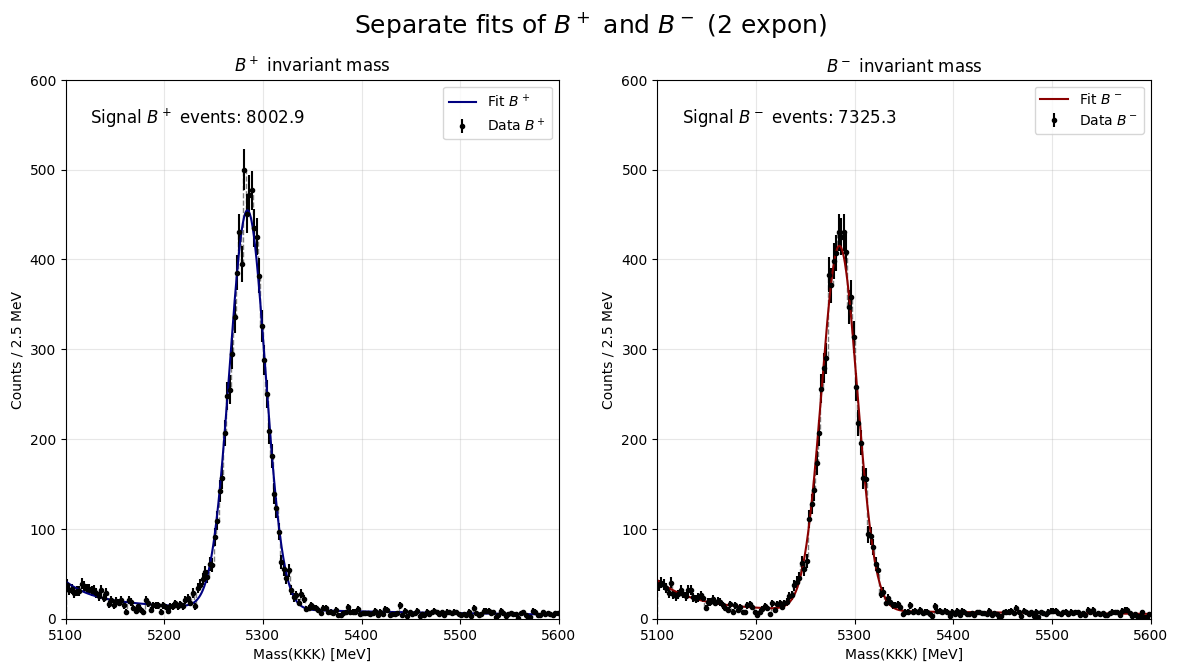

In [20]:
lf.plot_separate_fits(sep_fits, samples, cfg);

#### Goodness of fit ($\chi^2$)

In [21]:
for s, m in samples.items():
    f = sep_fits[s]
    print(f"--- {s}")
    print(lf.chi2_gof(m, lf.fitted_curve(f, cfg), cfg.fit_window, bins=200, n_free=f.nfit))

--- pos
Chi2:         247.66
NDOF:         193
Chi2 / NDOF:  1.283
p-value:      0.0048
--- neg
Chi2:         193.80
NDOF:         193
Chi2 / NDOF:  1.004
p-value:      0.4702


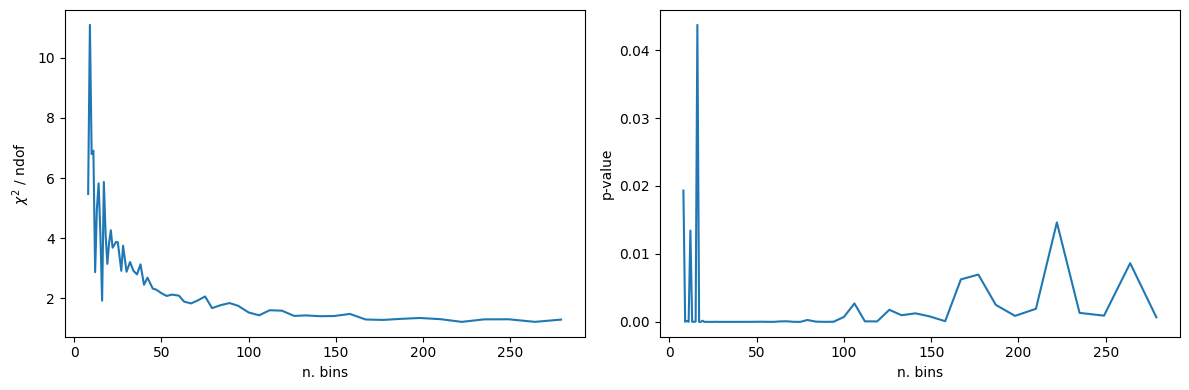

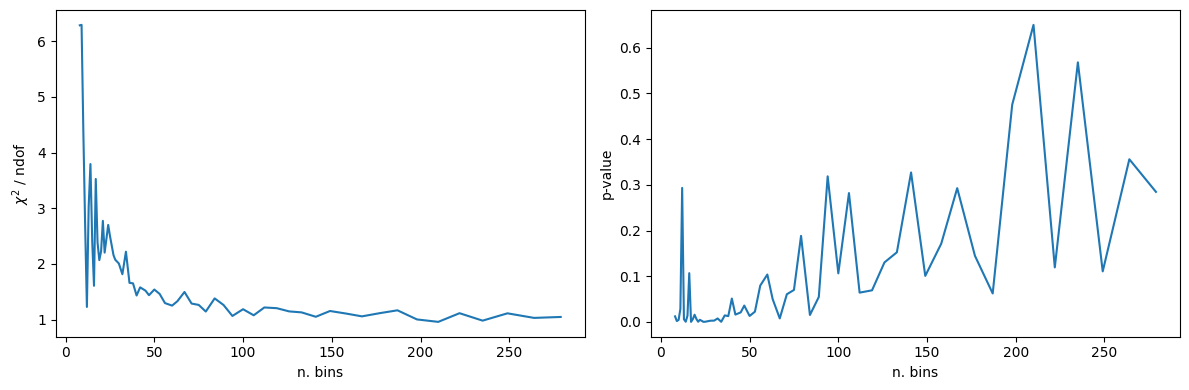

In [22]:
# chi2/ndof and p-value as a function of the number of bins (B+)
bin_values = np.unique(np.logspace(0, 3.5, 100, base=5).astype(int))
f = sep_fits["pos"]
chi2_red, p_vals = lf.scan_gof_bins(samples["pos"], lf.fitted_curve(f, cfg), cfg.fit_window, f.nfit, bin_values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(bin_values, chi2_red); axes[0].set(xlabel="n. bins", ylabel=r"$\chi^2$ / ndof")
axes[1].plot(bin_values, p_vals);   axes[1].set(xlabel="n. bins", ylabel="p-value")
fig.tight_layout()

# chi2/ndof and p-value as a function of the number of bins (B-)
bin_values = np.unique(np.logspace(0, 3.5, 100, base=5).astype(int))
f = sep_fits["neg"]
chi2_red, p_vals = lf.scan_gof_bins(samples["neg"], lf.fitted_curve(f, cfg), cfg.fit_window, f.nfit, bin_values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(bin_values, chi2_red); axes[0].set(xlabel="n. bins", ylabel=r"$\chi^2$ / ndof")
axes[1].plot(bin_values, p_vals);   axes[1].set(xlabel="n. bins", ylabel="p-value")
fig.tight_layout()

### Joint Fit

I want to do a joint fit for the B+ and B- peaks. 

The common parameters are:

- mu:    B+/B- mass, the same for both charges (fitted: about 5284.4 MeV)
- sigma: resolution, the same for B+/B- because the detector is symmetric
- N_sig: signal events (B+ and B-)
- A_CP:  CP asymmetry (N_sig_neg - N_sig_pos) / (N_sig_neg + N_sig_pos)

Specific parameters:

- For B+
    - N_bkg_pos:  events of bkgs
    - lam1_pos:   bkg1
    - lam2_pos:   bkg2
    - f_bkgs_pos: fraction of contribution bkg1 respect bkg2

- For B-
    - N_bkg_neg:  events of bkgs
    - lam1_neg:   bkg1
    - lam2_neg:   bkg2
    - f_bkgs_neg: fraction of contribution bkg1 respect bkg2

In [23]:
# 2 exponentials (default) and 1 exponential (simpler background model)
joint = {n: lf.fit_joint(samples, cfg, n_exp=n, minos=True) for n in (2, 1)}
display(joint[1])
display(joint[2])

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -1.232e+05                 │              Nfcn = 858              │
│ EDM = 6.33e-06 (Goal: 0.0002)    │            time = 1.5 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name      │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼───────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig     │  15.08e3  │  0.13e3   │  -0.13e3   │   0.13e3   │    0    │         │       │
│ 1 │ A_CP      │  -0.048   │   0.008   │   -0.008   │   0.008    │   -1    │    1    │       │
│ 2 │ mu        │ 5.28449e3 │ 0.00016e3 │ -0.00016e3 │ 0.00016e3  │  5200   │  5350   │       │
│ 3 │ sigma     │   17.64   │   0.13    │   -0.13    │    0.13    │    1    │   100   │       │
│ 4 │ N_bkg_pos │  2.39e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 5 │ lam1_pos  │  3.83e-3  │  0.16e-3  │  -0.15e-3  │  0.16e-3   │  1e-06  │    1    │       │
│ 6 │ N_bkg_neg │  2.26e3   │  0.05e3   │  -0.05e3   │   0.05e3   │    0    │         │       │
│ 7 │ lam1_neg  │  3.62e-3  │  0.16e-3  │  -0.16e-3  │  0.16e-3   │  1e-06  │    1    │       │
└───┴───────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         N_sig         │         A_CP          │          mu           │         sigma         │       N_bkg_pos       │       lam1_pos        │       N_bkg_neg       │       lam1_neg        │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │  -0.13e3  │  0.13e3   │  -0.008   │   0.008   │   -0.16   │   0.16    │   -0.13   │   0.13    │    -60    │    60     │ -0.15e-3  │  0.16e-3  │    -50    │    50     │ -0.16e-3  │  0.16e-3  │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ Max FCN  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ New Min  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
└──────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┘
┌───────────┬──────────────────────────────────────────────────────────────────────────────

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -1.234e+05                 │             Nfcn = 3317              │
│ EDM = 3.03e-05 (Goal: 0.0002)    │            time = 6.4 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name       │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig      │  15.33e3  │  0.13e3   │  -0.13e3   │   0.13e3   │    0    │         │       │
│ 1 │ A_CP       │  -0.044   │   0.008   │   -0.008   │   0.009    │   -1    │    1    │       │
│ 2 │ mu         │ 5.28438e3 │ 0.00016e3 │ -0.00016e3 │ 0.00016e3  │  5200   │  5350   │       │
│ 3 │ sigma      │   18.00   │   0.14    │   -0.14    │    0.14    │    1    │   100   │       │
│ 4 │ N_bkg_pos  │  2.29e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 5 │ lam1_pos   │   0.035   │   0.008   │   -0.007   │   0.008    │  1e-06  │    1    │       │
│ 6 │ lam2_pos   │  2.81e-3  │  0.28e-3  │  -0.29e-3  │  0.26e-3   │  1e-06  │    1    │       │
│ 7 │ f_bkgs_pos │   0.112   │   0.028   │   -0.024   │   0.030    │    0    │    1    │       │
│ 8 │ N_bkg_neg  │  2.11e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 9 │ lam1_neg   │   0.028   │   0.005   │   -0.004   │   0.005    │  1e-06  │    1    │       │
│ 10│ lam2_neg   │  1.6e-3   │  0.4e-3   │  -0.4e-3   │   0.4e-3   │  1e-06  │    1    │       │
│ 11│ f_bkgs_neg │   0.210   │   0.039   │   -0.035   │   0.040    │    0    │    1    │       │
└───┴────────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         N_sig         │         A_CP          │          mu           │         sigma         │       N_bkg_pos       │       lam1_pos        │       lam2_pos        │      f_bkgs_pos       │       N_bkg_neg       │       lam1_neg        │       lam2_neg        │      f_bkgs_neg       │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │  -0.13e3  │  0.13e3   │  -0.008   │   0.009   │   -0.16   │   0.16    │   -0.14   │   0.14    │    -60    │    60     │  -0.007   │   0.008   │ -0.29e-3  │  0.26e-3  │  -0.024   │   0.030   │    -60    │    60     │  -0.004   │   0.005   │  -0.4e-3  │  0.4e-3   │  -0.035   │   0.040   │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   Fals


=== 2 exponential(s) ===  valid: True
A_CP = -0.0441 ± 0.0085   (relative error 19.3%, Hesse significance 5.19 sigma)
Chi2:         159.53
NDOF:         88
Chi2 / NDOF:  1.813
p-value:      4.777014717533353e-06

=== 1 exponential(s) ===  valid: True
A_CP = -0.0481 ± 0.0085   (relative error 17.6%, Hesse significance 5.67 sigma)
Chi2:         294.06
NDOF:         92
Chi2 / NDOF:  3.196
p-value:      5.731655762052155e-23


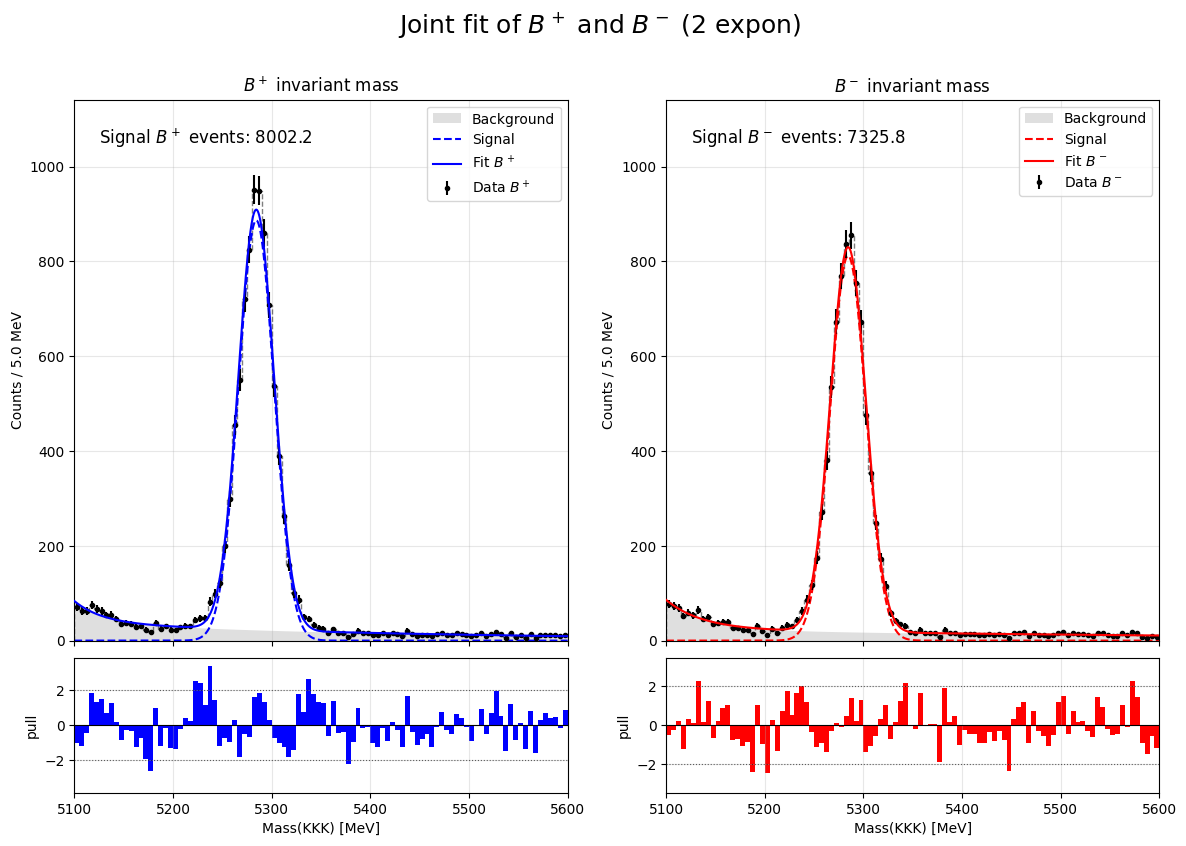

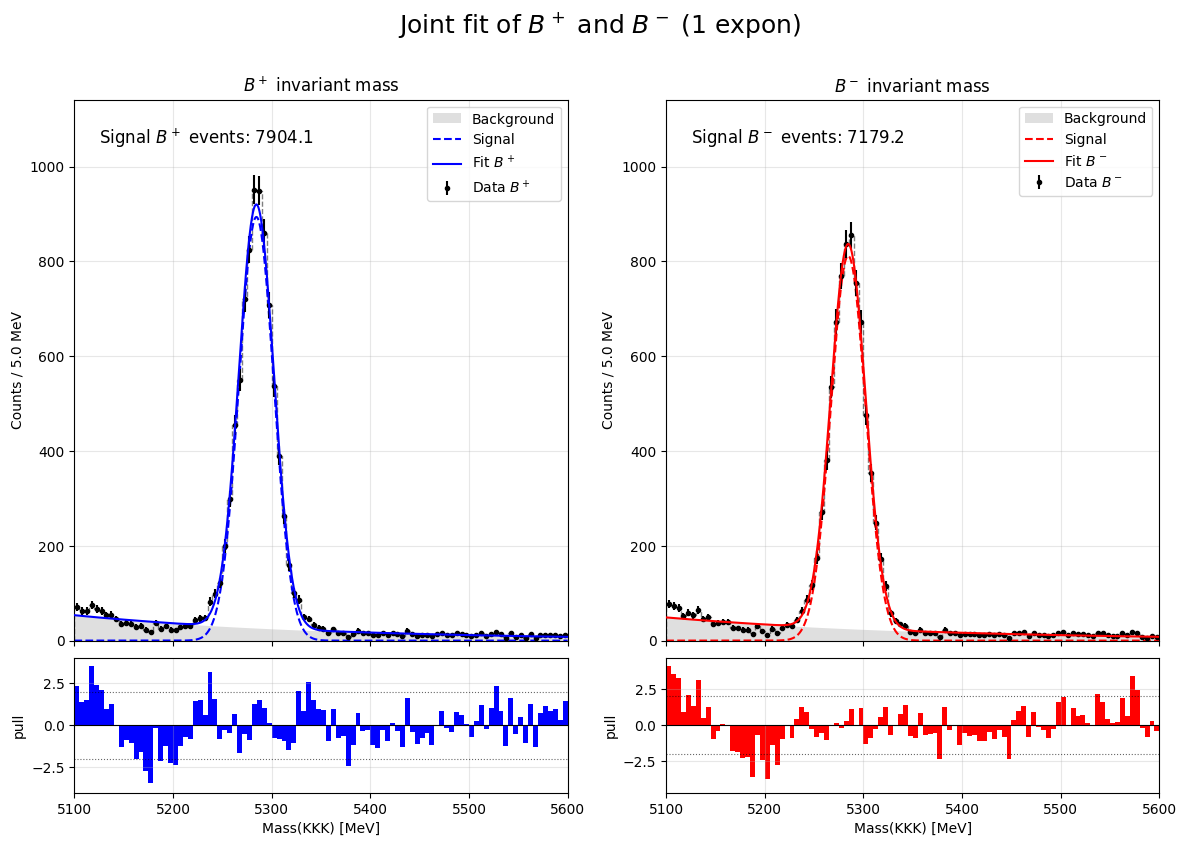

In [98]:
for n, m in joint.items():
    print(f"\n=== {n} exponential(s) ===  valid: {m.valid}")
    lf.print_asymmetry(m)
    print(lf.gof_joint(m, samples, cfg, n_exp=n, bins=50))
    lf.plot_joint_fit(m, samples, cfg, n_exp=n)

In [90]:
Ns = joint[2].values["N_sig"], joint[2].errors["N_sig"]
Nb = joint[2].values["N_bkg_pos"] + joint[2].values["N_bkg_neg"]
Nb_err = np.sqrt(joint[2].covariance["N_bkg_pos","N_bkg_pos"] + joint[2].covariance["N_bkg_neg","N_bkg_neg"]
                 + 2*joint[2].covariance["N_bkg_pos","N_bkg_neg"])

print('Ns: ', Ns[0], "±", Ns[1])
print('Nb (pos): ', joint[2].values["N_bkg_pos"], joint[2].errors["N_bkg_pos"])
print('Nb (neg): ', joint[2].values["N_bkg_neg"], joint[2].errors["N_bkg_neg"])
print('Nb: ', Nb, "±", Nb_err)
n_pos, n_neg = joint[2].values["N_bkg_pos"], joint[2].values["N_bkg_neg"]
n = n_pos + n_neg
a = (n_neg - n_pos) / n
print(f"asymm: {a:.3f} ± {np.sqrt((1 - a**2) / n):.3f}")

Ns:  15327.953800327161 ± 132.96598438037836
Nb (pos):  2290.0107403333354 57.60266431789864
Nb (neg):  2113.099519774695 55.65993609968973
Nb:  4403.110260108031 ± 82.1940162234028
asymm: -0.040 ± 0.015


In [114]:
print("A_CP: ", joint[2].values["A_CP"])
print(f'68% CL: [{joint[2].values["A_CP"]+joint[2].merrors["A_CP"].lower}, {joint[2].values["A_CP"]+joint[2].merrors["A_CP"].upper}]')
joint[2].minos("A_CP", cl=0.95)
print(f'95% CL: [{joint[2].values["A_CP"]+joint[2].merrors["A_CP"].lower}, {joint[2].values["A_CP"]+joint[2].merrors["A_CP"].upper}]')

A_CP:  -0.04412921444784368
68% CL: [-0.05258667519688764, -0.03561271029322588]
95% CL: [-0.06073745056651783, -0.027472100483883703]


### Profiled Likelihood and hypothesis test

In [25]:
best = joint[2]
POIS = ["A_CP", "mu"]                                        # parameters of interest
nuisance = [p for p in best.parameters if p not in POIS]     # everything else is profiled

t, p, _ = lf.wilks_test(best, {"A_CP": 0.0})                 # H0: no CP violation
# significance Z = sqrt(t) (likelihood ratio, one parameter), as in the report
print(f"H0: A_CP = 0  ->  t = {t:.2f},  p-value = {p:.2e}  (Z = sqrt(t) = {np.sqrt(t):.2f} sigma)")

H0: A_CP = 0  ->  t = 26.99,  p-value = 2.05e-07  (Z = sqrt(t) = 5.20 sigma)


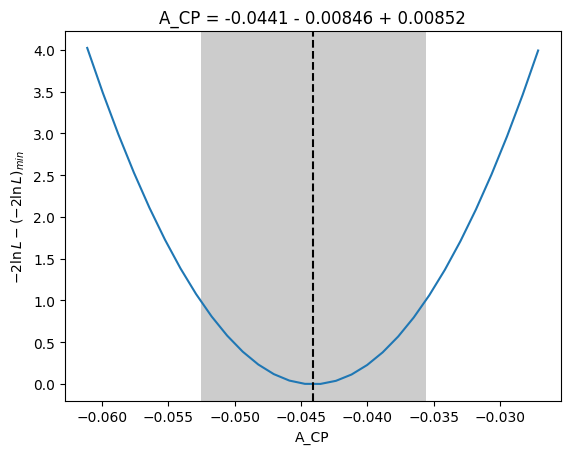

In [26]:
best.draw_mnprofile("A_CP")
plt.ylabel(r"$-2\ln L - (-2\ln L)_{min}$");

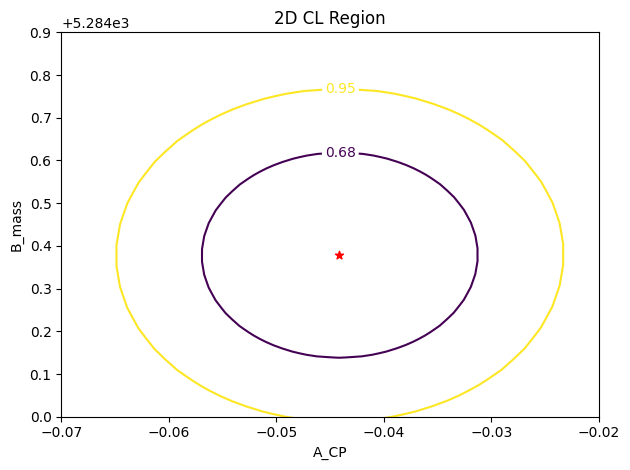

In [27]:
best.draw_mncontour("A_CP", "mu", cl=[0.68, 0.95])
plt.scatter([best.values["A_CP"]], [best.values["mu"]], marker="*", color="r")
plt.title("2D CL Region")
plt.xlabel("A_CP")
plt.ylabel("B_mass")
plt.xlim(-0.07, -0.020)
plt.ylim(5284.0, 5284.9)
plt.tight_layout()

### Coverage check (bootstrap) of Wilks' theorem

In [53]:
# coverage of the Wilks interval on A_CP alone (mu and all other parameters profiled,
# chi2_1 threshold at 68.3% = 0.99), with the nominal window: directly comparable with the 68% Bayesian credible
# interval on A. (Before: (A_CP, mu) plane, threshold 2.30, old window [5100, 6000] -> 67.2%.)
res = lf.run_coverage_study(data_window, cfg, best, pois=["A_CP"], n_toys=1000, seed=1)
p_cov = res.coverage; dp_cov = np.sqrt(p_cov * (1 - p_cov) / len(res.t_values))

  0%|          | 0/1000 [00:00<?, ?it/s]

coverage of the 1.00 (68.3%) threshold: 68.4% +- 1.5%   (1000 toys, 0 failed)


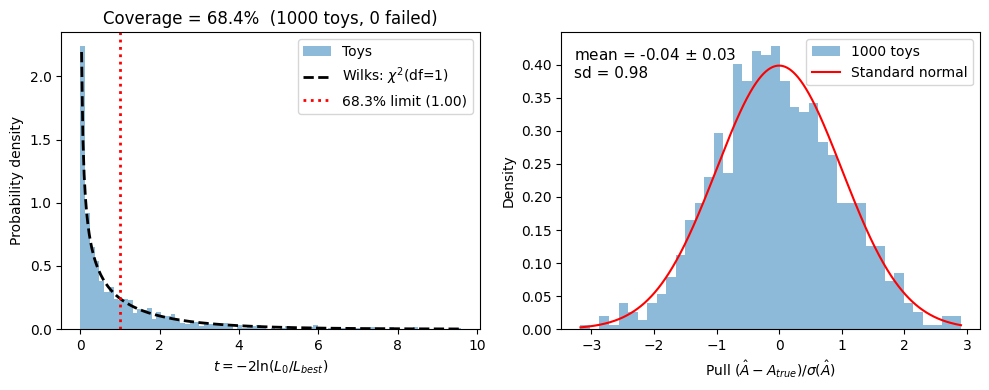

In [55]:
print(f"coverage of the {res.t_crit:.2f} (68.3%) threshold: {p_cov:.1%} +- {dp_cov:.1%}   ({len(res.t_values)} toys, {res.n_failed} failed)")
fig = lf.plot_coverage(res, best);
fig.savefig("results/frequentist_wilks_coverage.pdf")

### Stability Checks

1. Change the fit_window limits

In [ ]:
fit_window_limits = {
    'left':  [5000, 5050, 5100, 5150, 5200],
    'right': [5350, 5400, 5450, 5500, 5550, 5600, 5650, 5700, 5750, 5800, 5850, 5900, 5950, 6000, 6050, 6100]
}

In [57]:
res_win = lf.scan_fit_window(data, cfg, fit_window_limits["left"], fit_window_limits["right"])
ok_win = res_win[res_win.valid & res_win.accurate]

scan:   0%|          | 0/80 [00:00<?, ?it/s]

nominal A_CP = -0.04413 ± 0.00850 (stat)
mean A_CP    = -0.04512 ± 0.00175 (syst)
std over windows        = 0.00177
mean err over windows   = 0.00852
max |A_CP - nominal|    = 0.00482


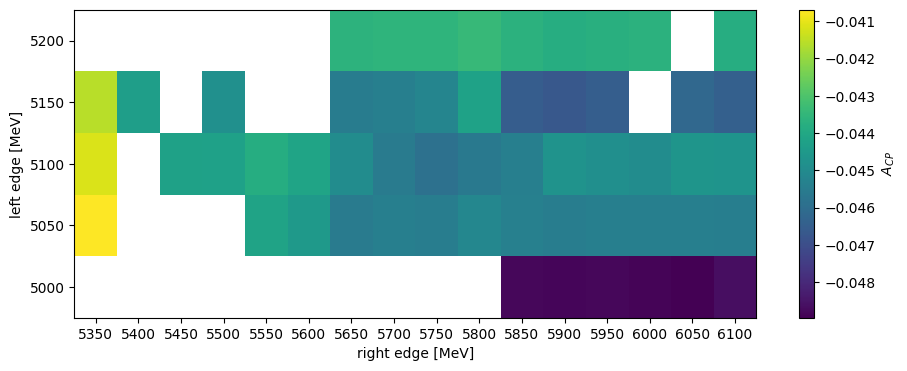

In [58]:
# note: all windows of the grid contain the nominal one, so the results are correlated and
# part of the spread is statistical (Barlow criterion: compare the shift with sqrt(|sigma_var^2 - sigma_nom^2|)).
# This scan is a stability check; the systematic uncertainty is the common study below.
# The same holds for the scan of the cuts.
nominal_win = ok_win[(ok_win.left == cfg.fit_window[0]) & (ok_win.right == cfg.fit_window[1])].iloc[0]

pivot_win = ok_win.pivot(index="left", columns="right", values="A_CP")
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.pcolormesh(pivot_win.columns, pivot_win.index, pivot_win.values, shading="nearest")
fig.colorbar(im, label=r"$A_{CP}$")
ax.set(xlabel="right edge [MeV]", ylabel="left edge [MeV]")
ax.set_xticks(pivot_win.columns)
ax.set_yticks(pivot_win.index)

print(f"nominal A_CP = {nominal_win.A_CP:.5f} ± {nominal_win.A_CP_err:.5f} (stat)")
print(f"mean A_CP    = {np.mean(ok_win['A_CP']):.5f} ± {np.std(ok_win['A_CP']):.5f} (syst)")
print(f"std over windows        = {ok_win.A_CP.std():.5f}")
print(f"mean err over windows   = {np.mean(ok_win.A_CP_err):.5f}")
print(f"max |A_CP - nominal|    = {(ok_win.A_CP - nominal_win.A_CP).abs().max():.5f}")

2. Change the sig_region limits

In [59]:
sig_region_limits = {
    'left':  [5150, 5170, 5185, 5200, 5215, 5230, 5250],
    'right': [5320, 5335, 5350, 5365, 5380, 5400, 5420]
}

In [60]:
# note: in the joint fit the signal region enters only the starting values (sideband fits)
# and the limit on mu, so A does not depend on it (spread 2e-5): a stability check of the fit, not a systematic.
res_sr  = lf.scan_signal_region(data, cfg, sig_region_limits['left'], sig_region_limits['right'])
ok_sr = res_sr[res_sr.valid & res_sr.accurate]

scan:   0%|          | 0/49 [00:00<?, ?it/s]

nominal A_CP = -0.04413 ± 0.00850 (stat)
mean A_CP    = -0.04411 ± 0.00002 (syst)
std over windows        = 0.00002
mean err over windows   = 0.00850
max |A_CP - nominal|    = 0.00006


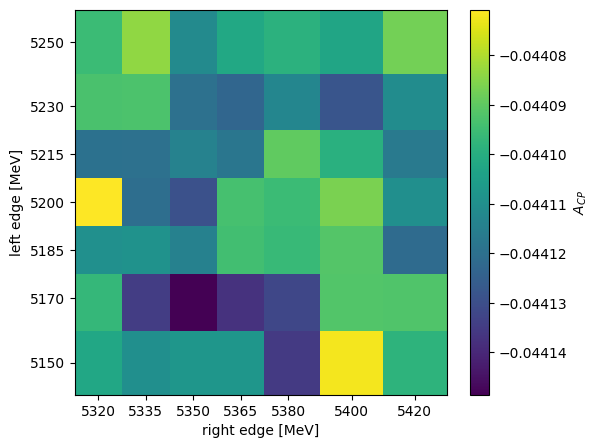

In [61]:
nominal_sr = ok_sr[(ok_sr.sig_lo == cfg.sig_region[0]) & (ok_sr.sig_hi == cfg.sig_region[1])].iloc[0]

pivot_sr = ok_sr.pivot(index="sig_lo", columns="sig_hi", values="A_CP")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.pcolormesh(pivot_sr.columns, pivot_sr.index, pivot_sr.values, shading="nearest")
fig.colorbar(im, label=r"$A_{CP}$")
ax.set(xlabel="right edge [MeV]", ylabel="left edge [MeV]")
ax.set_xticks(pivot_sr.columns)
ax.set_yticks(pivot_sr.index)

print(f"nominal A_CP = {nominal_sr.A_CP:.5f} ± {nominal_sr.A_CP_err:.5f} (stat)")
print(f"mean A_CP    = {np.mean(ok_sr['A_CP']):.5f} ± {np.std(ok_sr['A_CP']):.5f} (syst)")
print(f"std over windows        = {ok_sr.A_CP.std():.5f}")
print(f"mean err over windows   = {np.mean(ok_sr.A_CP_err):.5f}")
print(f"max |A_CP - nominal|    = {(ok_sr.A_CP - nominal_sr.A_CP).abs().max():.5f}")

3. Selection

In [62]:
scan_cuts = {
    "prob_k_min":   np.arange(0.45, 0.81, 0.025),
    "prob_pi_max":  np.arange(0.30, 0.56, 0.025),
}

In [63]:
# starts from `data_loose` (cuts looser than the grid), not from the sample already preselected with the nominal cuts
res_cuts  = lf.scan_preselection_cuts(data_loose, cfg, scan_cuts['prob_k_min'], scan_cuts['prob_pi_max'])
ok_cuts = res_cuts[res_cuts.valid & res_cuts.accurate]

scan:   0%|          | 0/165 [00:00<?, ?it/s]

nominal A_CP = -0.04413        ±   0.00850 (stat)
mean A_CP    = -0.04381 ± 0.00455 (syst)
std over windows        = 0.00457
mean err over windows   = 0.01121
max |A_CP - nominal|    = 0.01263


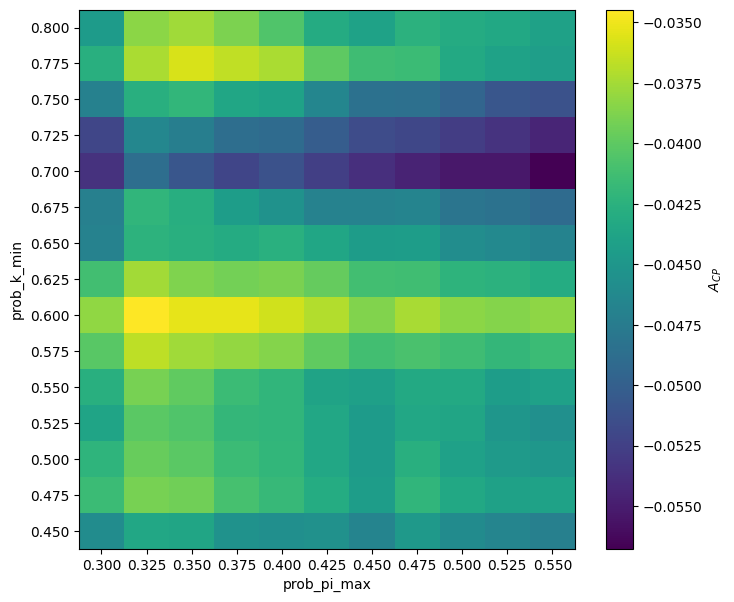

In [64]:
nominal_cuts = ok_cuts[(abs(ok_cuts.prob_k_min-cfg.prob_k_min) < 0.01) & (abs(ok_cuts.prob_pi_max-cfg.prob_pi_max) < 0.01)].iloc[0]

pivot_cuts = ok_cuts.pivot(index="prob_k_min", columns="prob_pi_max", values="A_CP")
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.pcolormesh(pivot_cuts.columns, pivot_cuts.index, pivot_cuts.values, shading="nearest")
fig.colorbar(im, label=r"$A_{CP}$")
ax.set(xlabel="prob_pi_max", ylabel="prob_k_min")
ax.set_xticks(pivot_cuts.columns)
ax.set_yticks(pivot_cuts.index)

print(f"nominal A_CP = {nominal_cuts.A_CP:.5f}        ±   {nominal_cuts.A_CP_err:.5f} (stat)")
print(f"mean A_CP    = {np.mean(ok_cuts['A_CP']):.5f} ± {np.std(ok_cuts['A_CP']):.5f} (syst)")
print(f"std over windows        = {ok_cuts.A_CP.std():.5f}")
print(f"mean err over windows   = {np.mean(ok_cuts.A_CP_err):.5f}")
print(f"max |A_CP - nominal|    = {(ok_cuts.A_CP - nominal_cuts.A_CP).abs().max():.5f}")

# Systematic study common to the Bayesian analysis (frequentist side) and charm vetoes

Same list of variants and same rule as the Bayesian analysis (`Bayesian/bayes_model.py`):

- **variants** (each = nominal model with a single change): window lower edge at 5050 and 5150, upper edge at 5450 and 5700 MeV; a single exponential; background shape shared by the two charges; symmetric background yields; Crystal Ball signal with free tails; $\mu,\sigma$ separate for the two charges; preselection ProbK $>0.4$ and $>0.6$, ProbPi $<0.4$ and $<0.6$ (one at a time);
- **rule**: for the variants that change the sample (window, preselection) a shift counts only if it exceeds $\sigma_B=\sqrt{|\sigma_{var}^2-\sigma_{nom}^2|}$ (Barlow); variants on the same sample whose $\chi^2$ is worse than the nominal one by more than 25 are excluded (rejected by the data); largest $|\Delta|$ per group, groups added in quadrature (`lf.combine_systematics`);
- **charm vetoes** (informative check, not in the systematic): $D^0$ only, and $D^0+J/\psi+\chi_{c0}$, world-average masses, $\pm30$ MeV for $D^0$ and $J/\psi$, $\pm60$ MeV for $\chi_{c0}$, on the two opposite-sign $K^+K^-$ pairs.

In [ ]:
# `data_loose` (cuts looser than every variant) and the nominal sample, defined above
nominal_sample = lf.select_window(data_loose[lf.kaon_preselection(data_loose, cfg)], cfg.fit_window)
print("candidates in the nominal window:", len(nominal_sample))

## Variants

In [2]:
VARIATIONS = [dict(label="nominal"),
    dict(label="window_lo5050", fit_window=(5050.0, 5600.0)), dict(label="window_lo5150", fit_window=(5150.0, 5600.0)),
    dict(label="window_hi5450", fit_window=(5100.0, 5450.0)), dict(label="window_hi5700", fit_window=(5100.0, 5700.0)),
    dict(label="bkg_single_exp", n_exp=1), dict(label="bkg_shared_shape", bkg_shape="shared"),
    dict(label="bkg_symmetric", bkg_yield="symmetric"),
    dict(label="signal_crystal_ball", signal="cb"), dict(label="signal_per_charge", signal_per_charge=True),
    dict(label="presel_probk_0.4", prob_k_min=0.4), dict(label="presel_probk_0.6", prob_k_min=0.6),
    dict(label="presel_probpi_0.4", prob_pi_max=0.4), dict(label="presel_probpi_0.6", prob_pi_max=0.6)]
GROUPS = {"window": ["window_lo5050", "window_lo5150", "window_hi5450", "window_hi5700"],
          "background": ["bkg_single_exp", "bkg_shared_shape", "bkg_symmetric"],
          "signal": ["signal_crystal_ball", "signal_per_charge"],
          "preselection": ["presel_probk_0.4", "presel_probk_0.6", "presel_probpi_0.4", "presel_probpi_0.6"]}
SAMPLE_CHANGING = GROUPS["window"] + GROUPS["preselection"]

res = lf.scan_config(data_loose, cfg, VARIATIONS)
cols = ["label", "valid", "accurate", "n_events", "A_CP", "A_CP_err", "chi2"]
print(res[cols].to_string())
nom = res[res.label == "nominal"].iloc[0]
syst = lf.combine_systematics(nom, [r for _, r in res.iterrows() if r.label != "nominal"], GROUPS, SAMPLE_CHANGING)
for k, v in syst["variations"].items():
    print(f"{k:22s} shift={v['shift']:+.4f}  sigma_B={v['sigma_barlow'] if v['sigma_barlow'] is None else round(v['sigma_barlow'], 4)}"
          f"  {'EXCLUDED (data)' if v['rejected_by_data'] else ('counts' if v['counts'] else 'does not count (Barlow)')}")
print("by group:", {k: round(v, 4) for k, v in syst["groups"].items()}, " total:", round(syst["total"], 4),
      " (statistical:", round(syst["sigma_stat"], 4), ")")

scan:   0%|          | 0/14 [00:00<?, ?it/s]

scan:   7%|▋         | 1/14 [00:01<00:15,  1.19s/it]

scan:  14%|█▍        | 2/14 [00:02<00:14,  1.17s/it]

scan:  21%|██▏       | 3/14 [00:03<00:10,  1.04it/s]

scan:  29%|██▊       | 4/14 [00:03<00:08,  1.13it/s]

...

scan:  86%|████████▌ | 12/14 [00:10<00:01,  1.08it/s]

scan:  93%|█████████▎| 13/14 [00:11<00:00,  1.19it/s]

scan: 100%|██████████| 14/14 [00:12<00:00,  1.14it/s]

scan: 100%|██████████| 14/14 [00:12<00:00,  1.14it/s]

                  label  valid  accurate  n_events      A_CP  A_CP_err        chi2
0               nominal   True      True     19731 -0.044129  0.008499  441.716011
1         window_lo5050   True      True     21164 -0.044503  0.008512  519.255452
2         window_lo5150   True     False     18566 -0.044590  0.004306  455.377177
3         window_hi5450   True      True     19004 -0.044222  0.008492  482.733917
4         window_hi5700   True      True     20191 -0.045537  0.008500  473.802492
5        bkg_single_exp   True      True     19731 -0.048060  0.008471  576.264524
6      bkg_shared_shape   True      True     19731 -0.048143  0.008342  451.063731
7         bkg_symmetric   True      True     19731 -0.047238  0.008387  448.433676
8   signal_crystal_ball   True      True     19731 -0.044729  0.008477  406.794596
9     signal_per_charge   True      True     19731 -0.044245  0.008668  441.464469
10     presel_probk_0.4   True      True     26553 -0.047306  0.007640  444.521015
11  

## Charm vetoes (informative check)

In [3]:
vetoes = {}
for name, mode in (("veto_D0", "D"), ("veto_D0_Jpsi_chic0", "all")):
    d = lf.remove_charm_resonances(cfg, nominal_sample, mode)
    m = lf.fit_joint(lf.split_by_charge(d, col="B_Mass"), cfg)
    vetoes[name] = dict(n=int(len(d)), A_CP=float(m.values["A_CP"]), A_CP_err=float(m.errors["A_CP"]),
                        shift=float(m.values["A_CP"] - nom.A_CP), valid=bool(m.valid), accurate=bool(m.accurate))
    print(f"{name:20s} n={len(d)}  A_raw = {m.values['A_CP']:.4f} +- {m.errors['A_CP']:.4f}  (shift {m.values['A_CP'] - nom.A_CP:+.4f})")
assert vetoes["veto_D0"]["n"] == 18744 and vetoes["veto_D0_Jpsi_chic0"]["n"] == 16367, "candidate counts differ from the agreed ones"

veto_D0              n=18744  A_raw = -0.0493 +- 0.0087  (shift -0.0052)


veto_D0_Jpsi_chic0   n=16367  A_raw = -0.0421 +- 0.0094  (shift +0.0021)


## Save

In [4]:
def _clean(x):
    if isinstance(x, (np.floating, np.integer, np.bool_)):
        return x.item()
    return x
out = {"nominal": {k: _clean(nom[k]) for k in ("A_CP", "A_CP_err", "chi2", "n_events")},
       "variations": [{k: _clean(v) for k, v in r.items() if k != "gof"} for _, r in res.iterrows()],
       "systematics": syst, "charm_vetoes": vetoes, "groups": GROUPS, "sample_changing": SAMPLE_CHANGING}
with open(RESULTS_DIR / "freq_systematics.json", "w") as f:
    json.dump(out, f, indent=1, default=str)
print("[saved]", RESULTS_DIR / "freq_systematics.json")

[saved] /Users/gmoretti/Work/wt_freq/LHCb/Code_general/Frequentist/results/freq_systematics.json


## Fine scan of the PID cuts (stability check)

One cut at a time, in steps of 0.05, to tell a trend with the cut from a fluctuation of the single value used in the systematic study (`presel_probk_0.6`). Every sample is nested in the nominal one (or contains it): the expected fluctuation of the shift is $\sigma_B=\sqrt{|\sigma_v^2-\sigma_n^2|}$. The combination rule of the systematic study is not changed.

In [5]:
k_grid = [round(x, 2) for x in np.arange(0.30, 0.851, 0.05) if abs(x - 0.5) > 1e-9]
pi_grid = [round(x, 2) for x in np.arange(0.15, 0.701, 0.05) if abs(x - 0.5) > 1e-9]
scan_var = [dict(label="nominal")] + [dict(label=f"probk_{k:.2f}", prob_k_min=k) for k in k_grid] \
    + [dict(label=f"probpi_{p:.2f}", prob_pi_max=p) for p in pi_grid]
scan = lf.scan_config(data_scan, cfg, scan_var)
nom_s = scan[scan.label == "nominal"].iloc[0]
rows = []
for _, r in scan.iterrows():
    sb = float(np.sqrt(abs(r.A_CP_err ** 2 - nom_s.A_CP_err ** 2)))
    rows.append({"label": r.label, "prob_k_min": float(r.prob_k_min), "prob_pi_max": float(r.prob_pi_max), "n_events": int(r.n_events),
                 "A_CP": float(r.A_CP), "A_CP_err": float(r.A_CP_err), "shift": float(r.A_CP - nom_s.A_CP), "sigma_barlow": sb,
                 "pull": float((r.A_CP - nom_s.A_CP) / sb) if sb > 0 else 0.0, "valid": bool(r.valid), "accurate": bool(r.accurate)})
    print(f"{r.label:12s} n={int(r.n_events):6d}  A_raw={r.A_CP:+.4f} +- {r.A_CP_err:.4f}  shift={r.A_CP - nom_s.A_CP:+.4f}  sigma_B={sb:.4f}")
with open(RESULTS_DIR / "freq_pid_scan.json", "w") as f:
    json.dump({"nominal_A": float(nom_s.A_CP), "rows": rows}, f, indent=1)
print("[saved]", RESULTS_DIR / "freq_pid_scan.json")


scan:   0%|          | 0/23 [00:00<?, ?it/s]

scan:   4%|▍         | 1/23 [00:00<00:16,  1.30it/s]

scan:   9%|▊         | 2/23 [00:01<00:21,  1.03s/it]

scan:  13%|█▎        | 3/23 [00:03<00:21,  1.08s/it]

scan:  17%|█▋        | 4/23 [00:04<00:19,  1.04s/it]

...

scan:  91%|█████████▏| 21/23 [00:12<00:01,  1.53it/s]

scan:  96%|█████████▌| 22/23 [00:13<00:00,  1.49it/s]

scan: 100%|██████████| 23/23 [00:13<00:00,  1.46it/s]

scan: 100%|██████████| 23/23 [00:13<00:00,  1.66it/s]

nominal      n= 19731  A_raw=-0.0441 +- 0.0085  shift=+0.0000  sigma_B=0.0000
probk_0.30   n= 33328  A_raw=-0.0552 +- 0.0072  shift=-0.0111  sigma_B=0.0045
probk_0.35   n= 29279  A_raw=-0.0508 +- 0.0074  shift=-0.0067  sigma_B=0.0041
probk_0.40   n= 26553  A_raw=-0.0473 +- 0.0076  shift=-0.0032  sigma_B=0.0037
probk_0.45   n= 23899  A_raw=-0.0461 +- 0.0079  shift=-0.0019  sigma_B=0.0031
probk_0.55   n= 17112  A_raw=-0.0433 +- 0.0090  shift=+0.0009  sigma_B=0.0030
probk_0.60   n= 13981  A_raw=-0.0384 +- 0.0099  shift=+0.0058  sigma_B=0.0050
probk_0.65   n= 11354  A_raw=-0.0459 +- 0.0108  shift=-0.0017  sigma_B=0.0067
probk_0.70   n=  8649  A_raw=-0.0553 +- 0.0123  shift=-0.0112  sigma_B=0.0089
probk_0.75   n=  6857  A_raw=-0.0495 +- 0.0137  shift=-0.0054  sigma_B=0.0108
probk_0.80   n=  4769  A_raw=-0.0431 +- 0.0163  shift=+0.0010  sigma_B=0.0139
probk_0.85   n=  3322  A_raw=-0.0419 +- 0.0193  shift=+0.0022  sigma_B=0.0174
probpi_0.15  n= 10831  A_raw=-0.0446 +- 0.0111  shift=-0.0004  s

# Dalitz plots

Squared invariant masses of the two opposite-sign $K^+K^-$ pairs; charm resonances are visible as bands and are removed with the vetoes of `lhcb_freq.py`.

### Simulation Data

In [65]:
# For Simulation Data the charges are mixed
df_sim[['H1_Charge', 'H2_Charge', 'H3_Charge', 'B_Charge']][:5]

,H1_Charge,H2_Charge,H3_Charge,B_Charge
0,-1,1,-1,-1
1,1,-1,-1,-1
2,-1,1,1,1
3,1,-1,1,1
4,-1,1,-1,-1


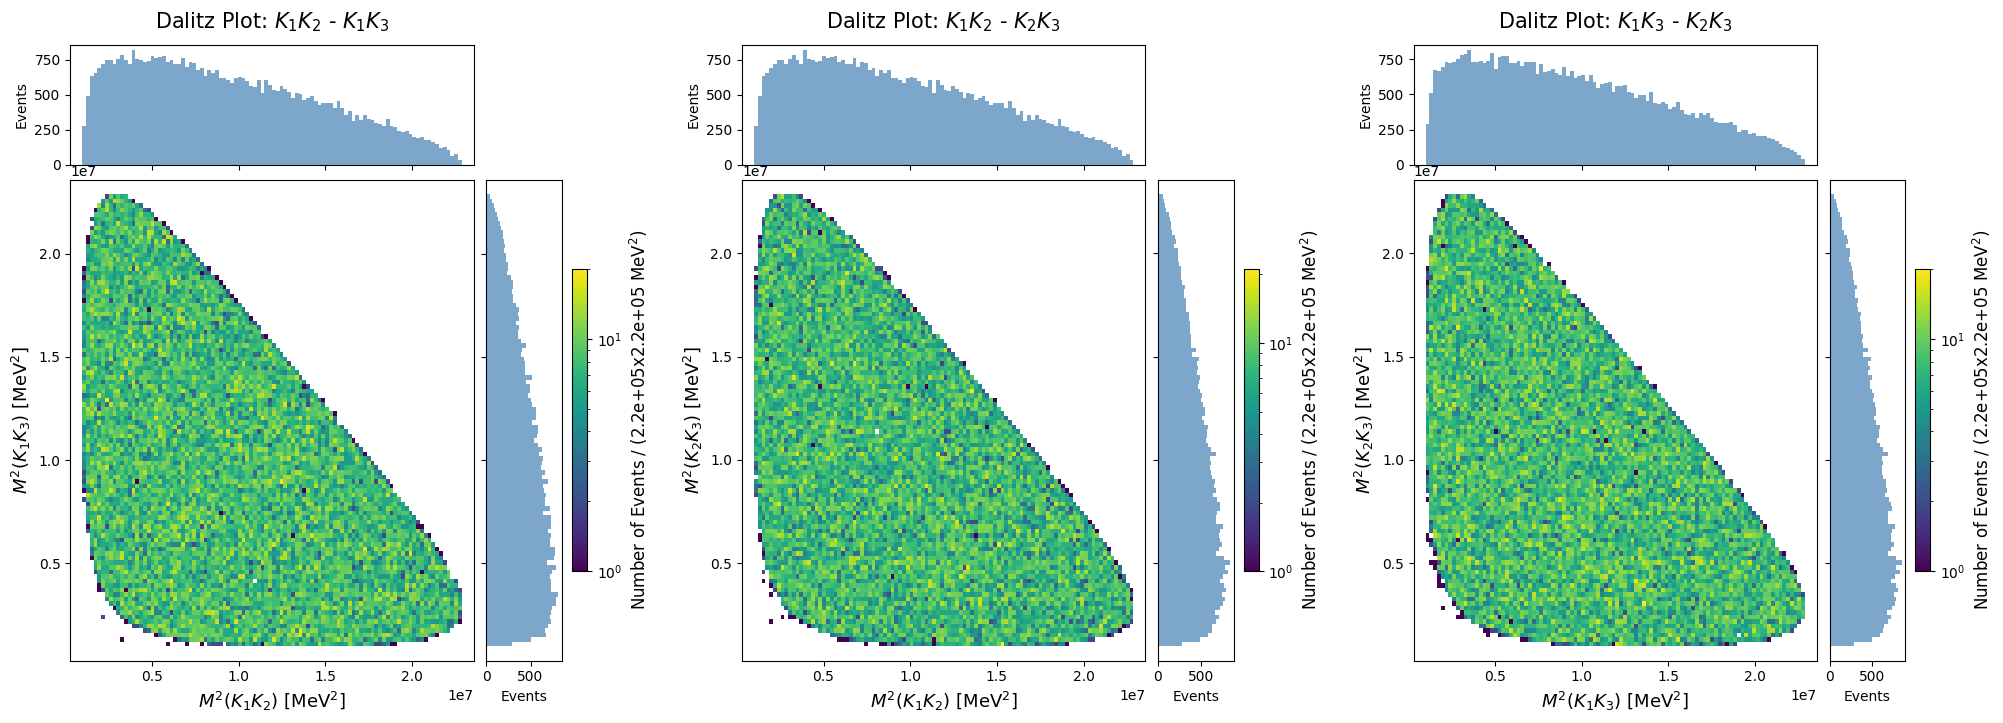

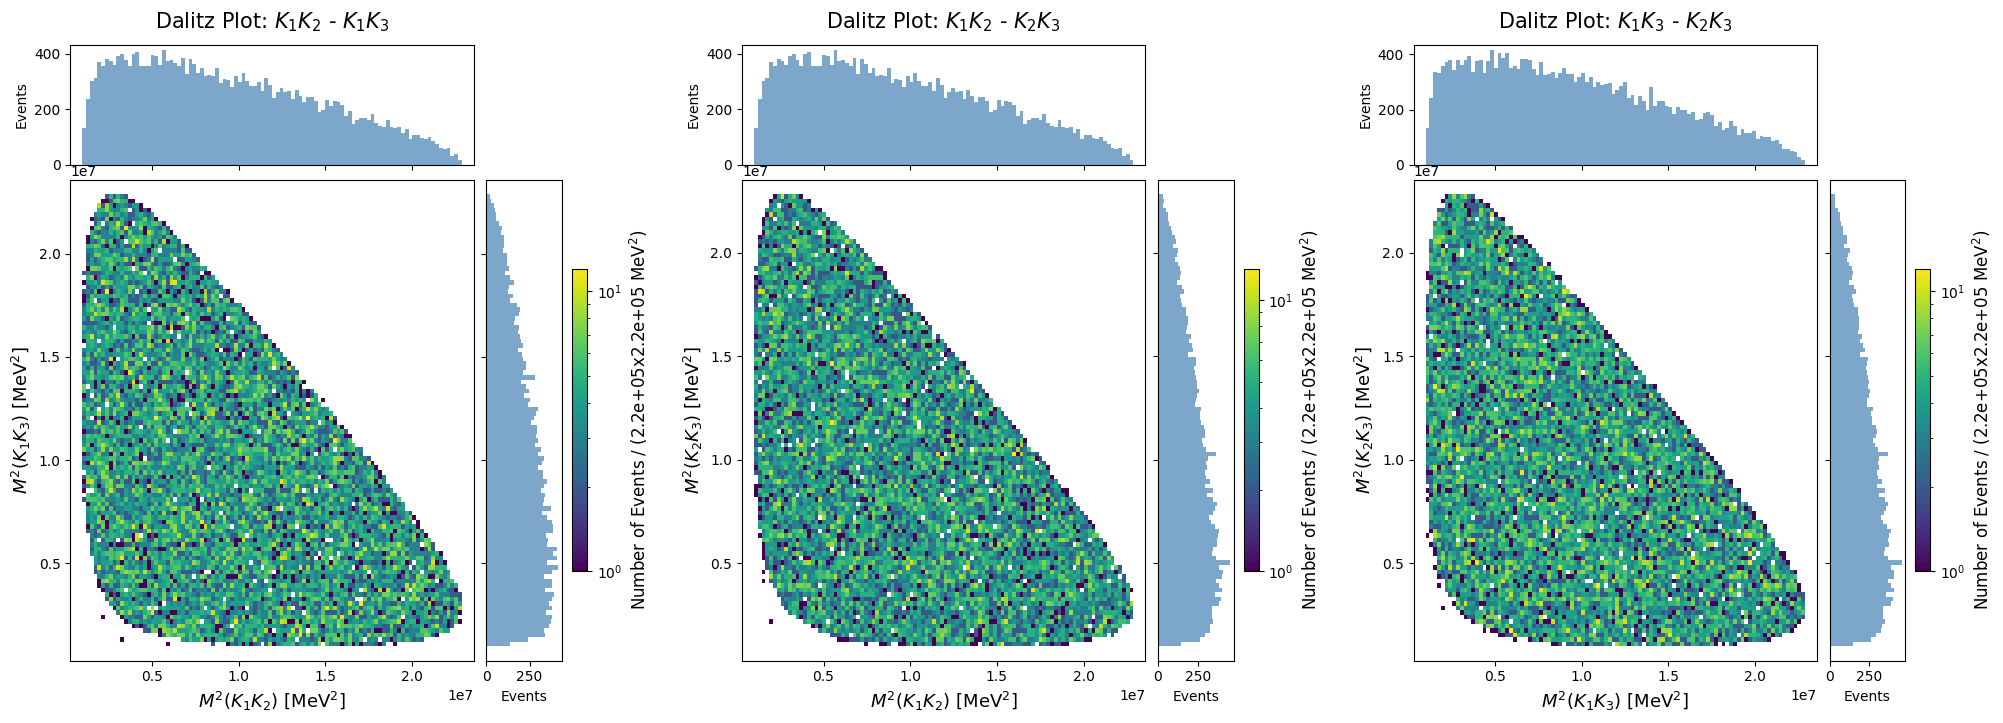

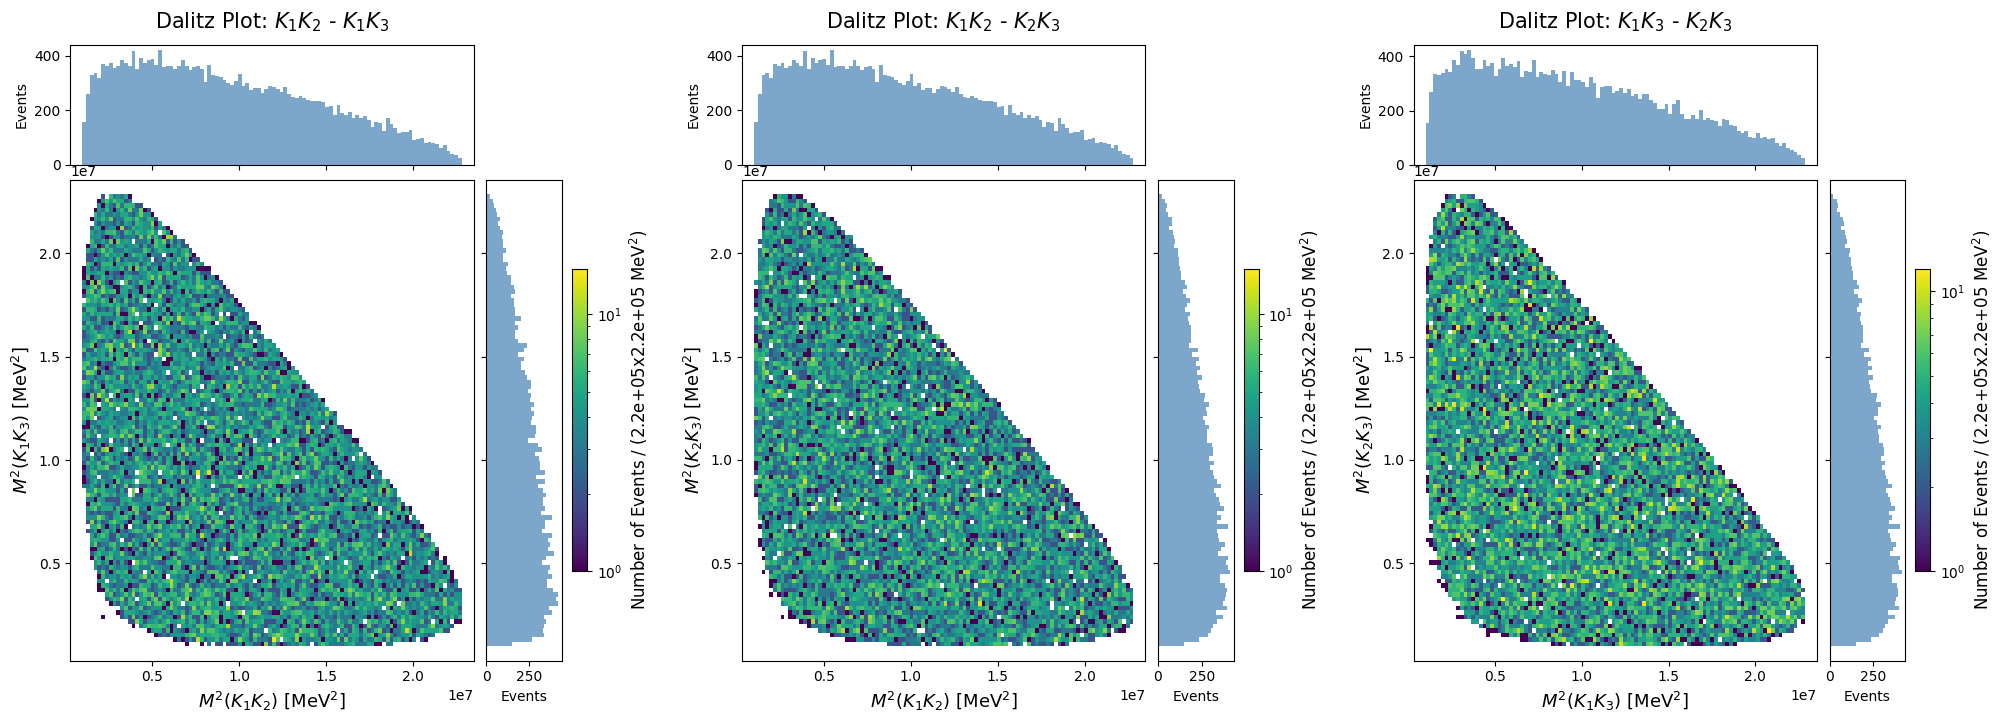

In [66]:
df_sim_charge_split = lf.split_by_charge(df_sim, col=df_sim.columns)
fig = lf.dalitz_plot(cfg, data=df_sim,                     bins=100)
fig = lf.dalitz_plot(cfg, data=df_sim_charge_split['pos'], bins=100)
fig = lf.dalitz_plot(cfg, data=df_sim_charge_split['neg'], bins=100)

### Real Data

#### Basic Dalitz Plot

In [67]:
# For Real Data the charge of 2 and 3 is the same (also equal to B charge)
#    --> 12 = 0
#    --> 13 = 0
#    --> 23 = ++/-- (should be no peak of M_23 in the Dalitz Plot) --> OK!

data[['H1_Charge', 'H2_Charge', 'H3_Charge', 'B_Charge']][:5]

,H1_Charge,H2_Charge,H3_Charge,B_Charge
0,-1,1,1,1
1,1,-1,-1,-1
2,-1,1,1,1
3,-1,1,1,1
4,1,-1,-1,-1


In [68]:
# # apply a cut on the B mass values (signal) to reduce the bkg
# data_signal = lf.select_window(data, cfg.sig_region)
# data_signal = data
# # plt.hist(data_signal['B_Mass'], bins=100);

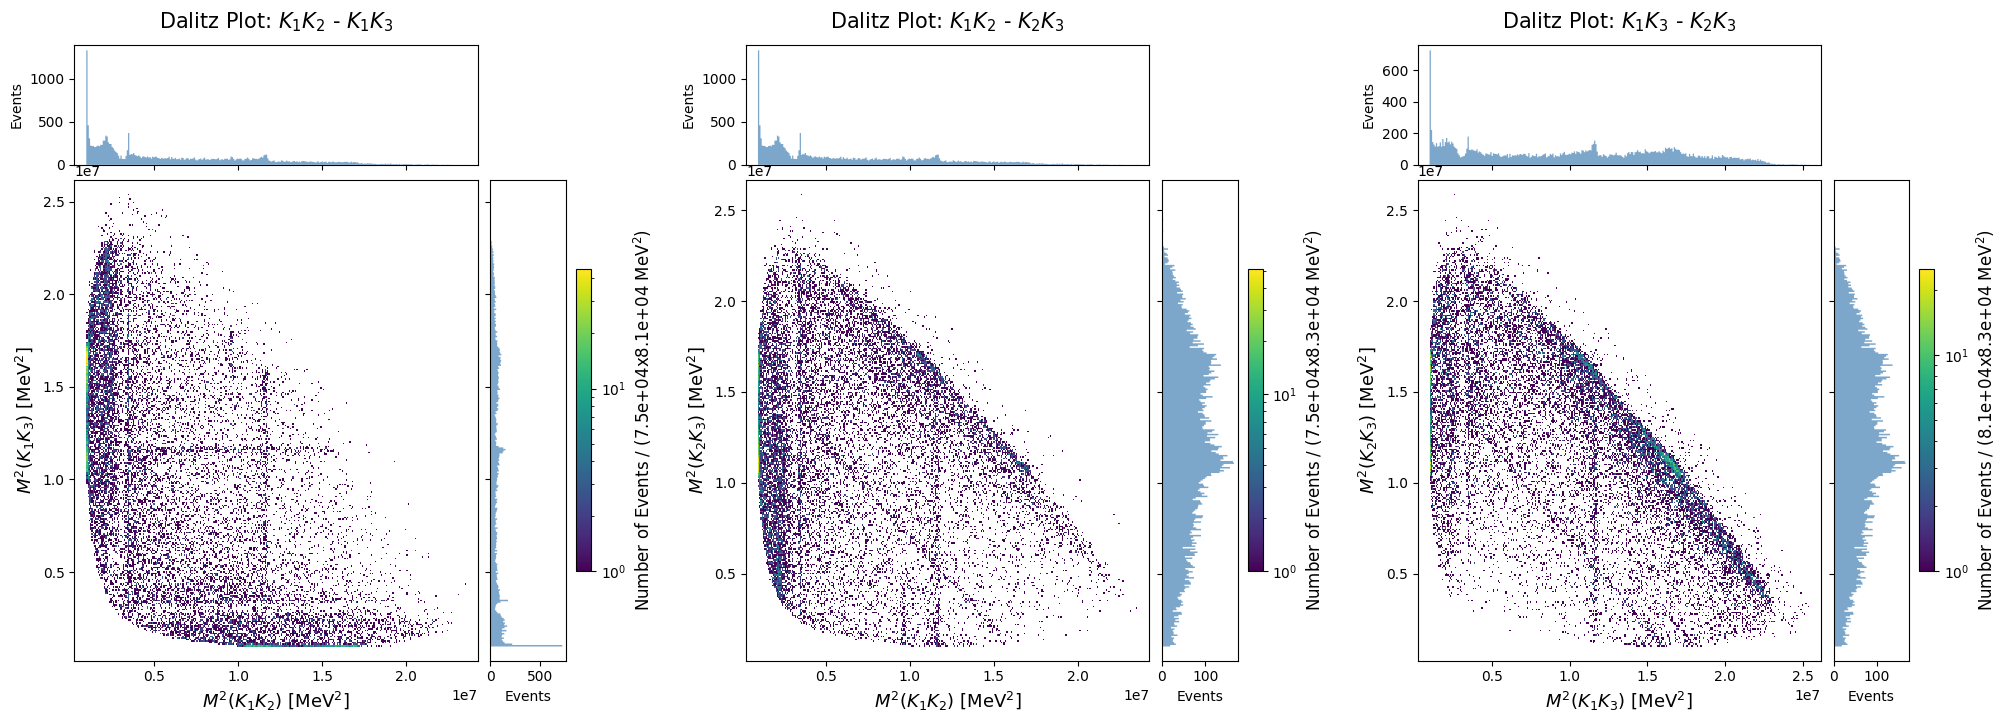

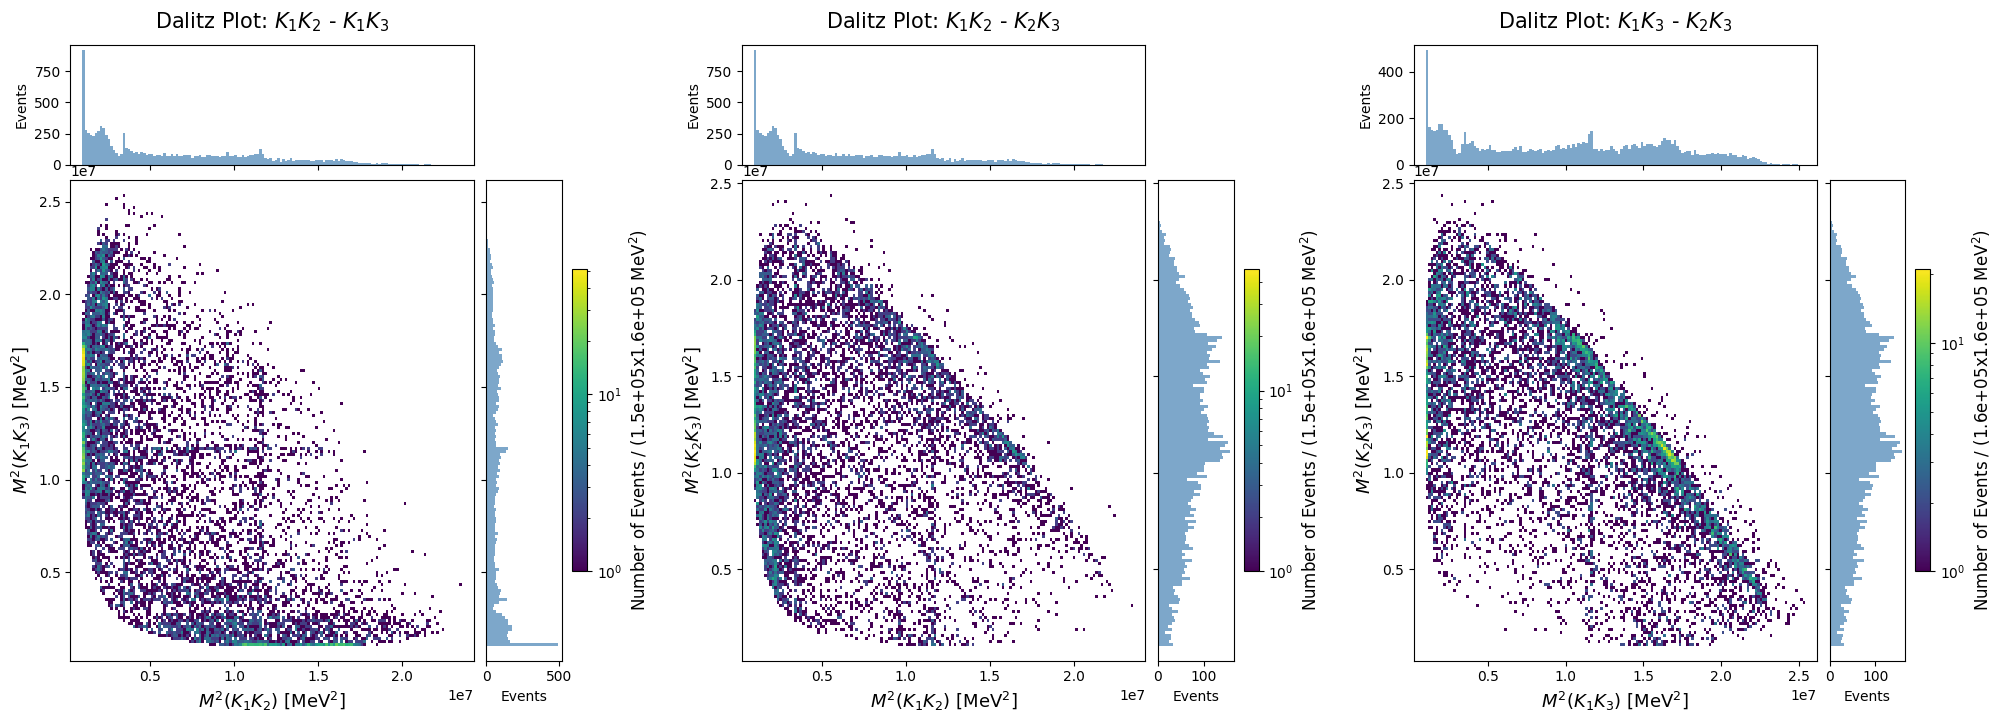

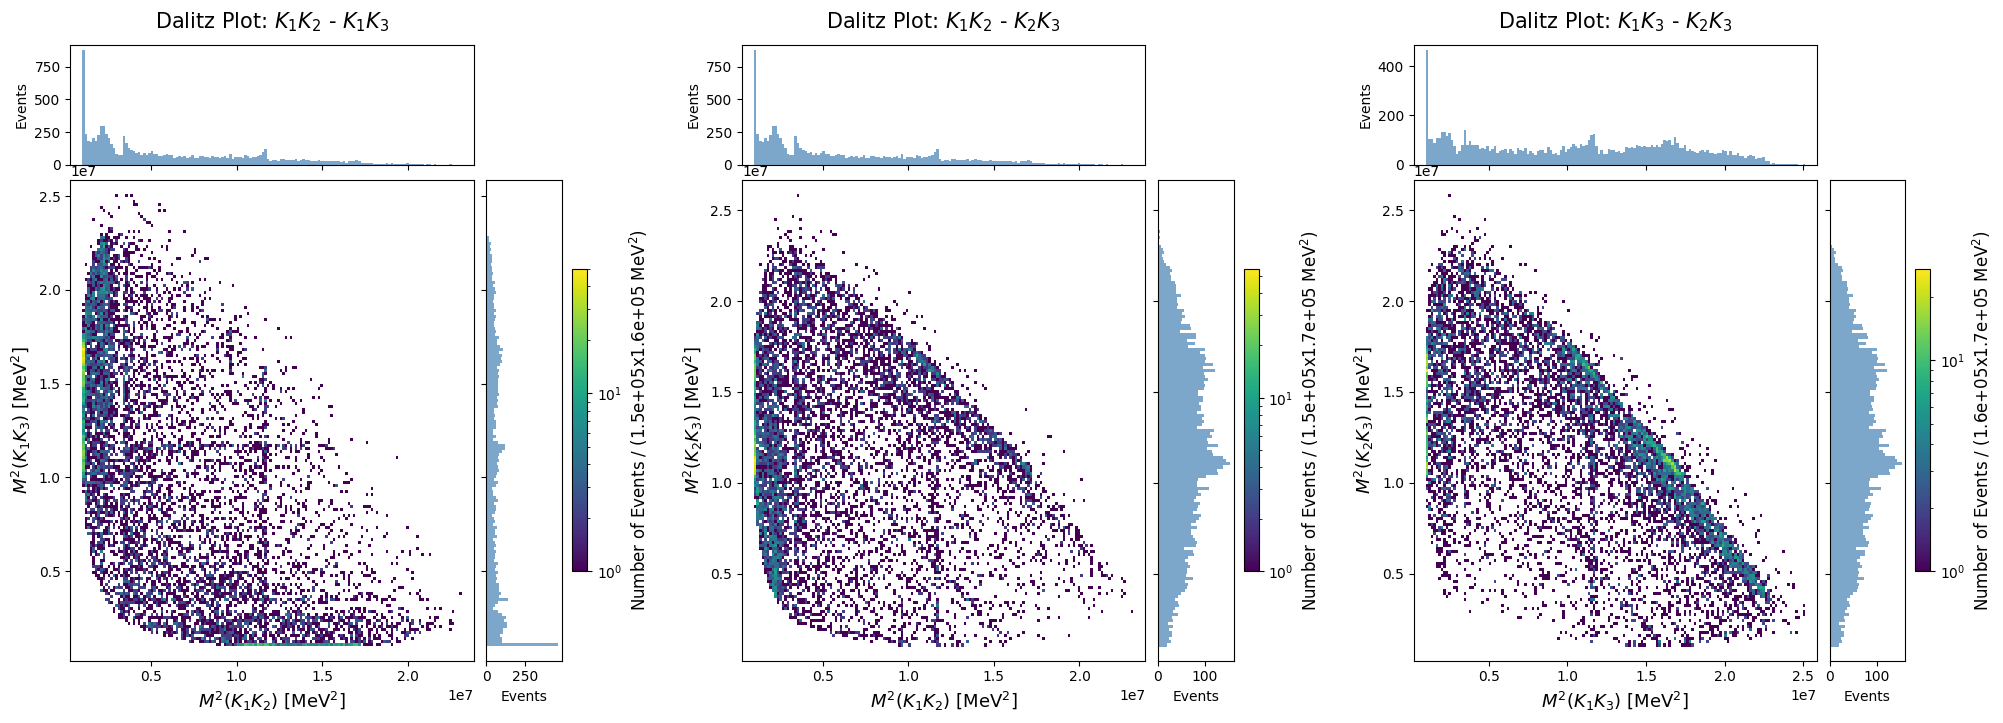

In [69]:
data_charge_split = lf.split_by_charge(data_window, col=data.columns)
fig, *_ = lf.dalitz_plot(cfg, data=data_window,              bins=300)
fig, *_ = lf.dalitz_plot(cfg, data=data_charge_split['pos'], bins=150)
fig, *_ = lf.dalitz_plot(cfg, data=data_charge_split['neg'], bins=150)

B charge:  pos
   Mass:  1865.475810617763 MeV
   Mass:  3398.529093593286 MeV
B charge:  neg
   Mass:  1865.475810617763 MeV
   Mass:  3398.529093593286 MeV


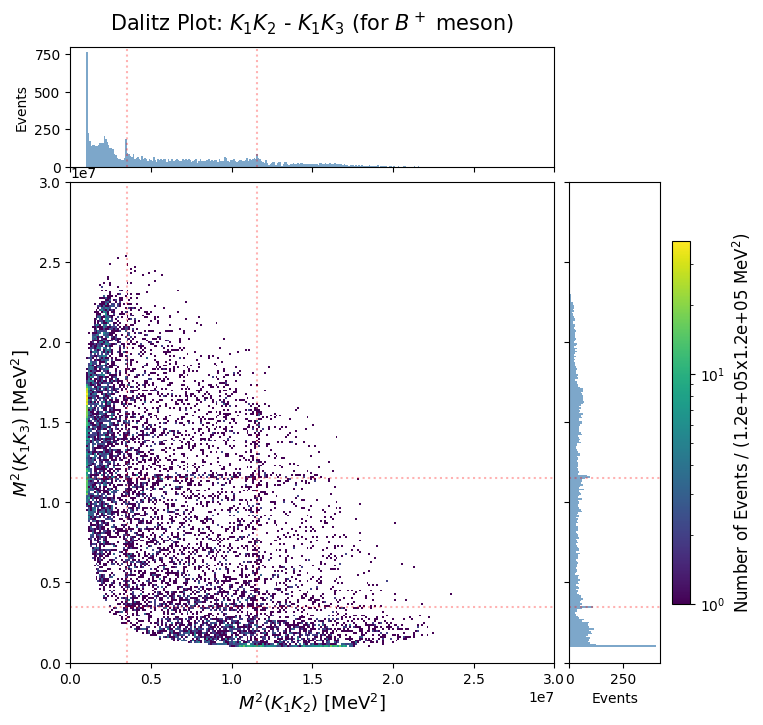

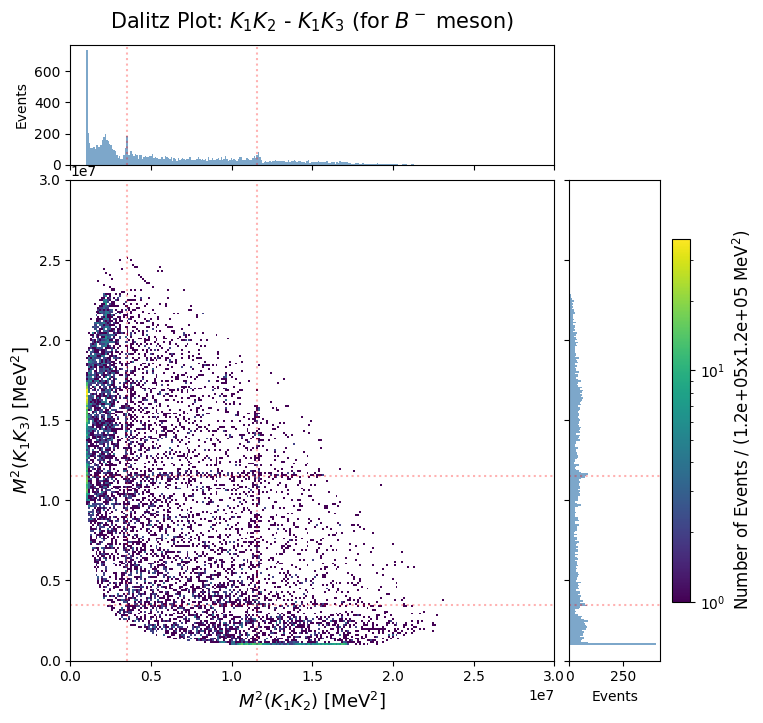

In [70]:
for charge, data_split in data_charge_split.items():
    print("B charge: ", charge)
    interesting_mass = {}
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    interesting_mass['12'] = all_mass['12']
    interesting_mass['13'] = all_mass['13']

    fig, ax, ax_top, ax_left, *_ = lf.dalitz_plot(cfg, mass=interesting_mass, bins=250, range=[[0,3e7],[0,3e7]],
                                                    add_title=r' (for $B^+$ meson)' if charge=='pos' else r' (for $B^-$ meson)')

    possible_peaks = [0.348e7, 1.155e7]
    for possible_peak in possible_peaks:
        ax.axvline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        ax.axhline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        ax_top.axvline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        ax_left.axhline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        print("   Mass: ", np.sqrt(possible_peak), "MeV")

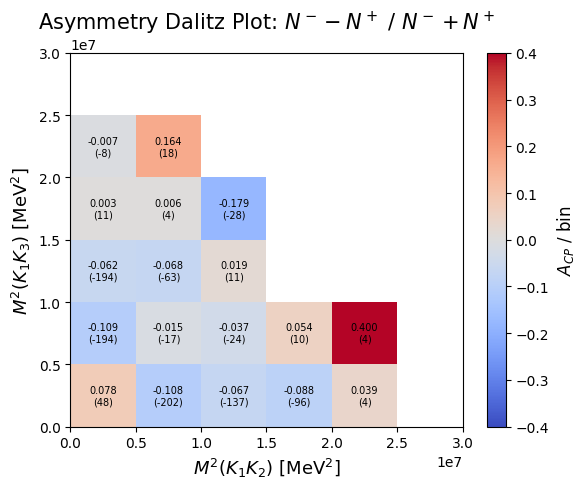

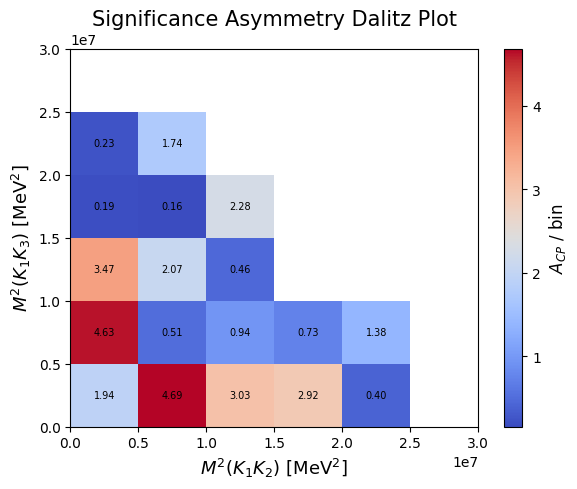

In [71]:
bins_histo_asymm=6

histo = {}
for charge, data_split in data_charge_split.items():
    # print("B charge: ", charge)
    interesting_mass = {}
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    interesting_mass['12'] = all_mass['12']
    interesting_mass['13'] = all_mass['13']

    fig, ax, ax_top, ax_left, *histo[charge] = lf.dalitz_plot(cfg, mass=interesting_mass, bins=bins_histo_asymm, range=[[0,3e7],[0,3e7]],
                                                    add_title=r' (for $B^+$ meson)' if charge=='pos' else r' (for $B^-$ meson)')
    plt.close()


x_centers = np.array((histo['neg'][1][:-1] + histo['neg'][1][1:]) / 2)
y_centers = np.array((histo['neg'][2][:-1] + histo['neg'][2][1:]) / 2)

with np.errstate(divide='ignore', invalid='ignore'):
    histo_diff = histo['neg'][0] - histo['pos'][0]
    histo_A_CP, histo_err_A_CP = lf.raw_asymmetry(histo['pos'][0], histo['neg'][0])
    histo_A_CP = np.nan_to_num(histo_A_CP, nan=0.0)
    histo_err_A_CP = np.nan_to_num(histo_err_A_CP, nan=0.0)

histo_A_CP_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, histo_A_CP)
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.pcolormesh(
    histo['pos'][1], histo['pos'][2], histo_A_CP_masked.T,
    cmap='coolwarm', 
    norm=CenteredNorm(vcenter=0)
)
for i in np.arange(len(x_centers)):
    for j in np.arange(len(y_centers)):
        val1 = histo_diff[i, j]
        val2 = histo_A_CP[i, j]
        err_val2 = histo_err_A_CP[i, j]
        
        if abs(val1) > 1:
            ax.text(
                x_centers[i],
                y_centers[j],
                f"{val2:.3f}\n({int(val1)})",
                ha='center',
                va='center',
                fontsize=7,
                color='black'
            )

ax.set_xlabel(r"$M^2(K_1K_2)$ [MeV$^2$]", fontsize=13)
ax.set_ylabel(r"$M^2(K_1K_3)$ [MeV$^2$]", fontsize=13)
ax.set_title(r"Asymmetry Dalitz Plot: $N^- - N^+$ / $N^- + N^+$", fontsize=15)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$A_{CP}$ / bin", fontsize=12)
fig.tight_layout()
plt.show()

# -----------------------------------------------------------------------------------------------------------

histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.pcolormesh(
    histo['pos'][1], histo['pos'][2], histo_significance_masked.T, 
    cmap='coolwarm', 
    # norm=CenteredNorm(vcenter=0)
)

for i in np.arange(len(x_centers)):
    for j in np.arange(len(y_centers)):
        val1 = histo_diff[i, j]
        val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])
        if abs(val1) > 1:
            ax.text(
                x_centers[i],
                y_centers[j],
                f"{val2:.2f}",
                ha='center',
                va='center',
                fontsize=7,
                color='black'
            )

ax.set_xlabel(r"$M^2(K_1K_2)$ [MeV$^2$]", fontsize=13)
ax.set_ylabel(r"$M^2(K_1K_3)$ [MeV$^2$]", fontsize=13)
ax.set_title(r"Significance Asymmetry Dalitz Plot", fontsize=15)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$A_{CP}$ / bin", fontsize=12)
fig.tight_layout()
plt.show()

#### Removing Charm Resonances

**Dalitz Plot**

B charge:  pos
B charge:  neg


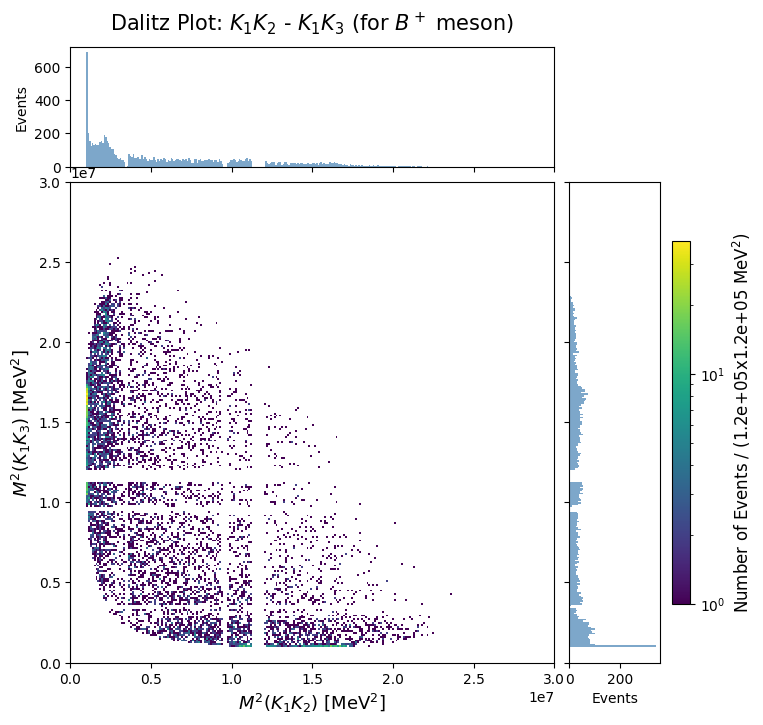

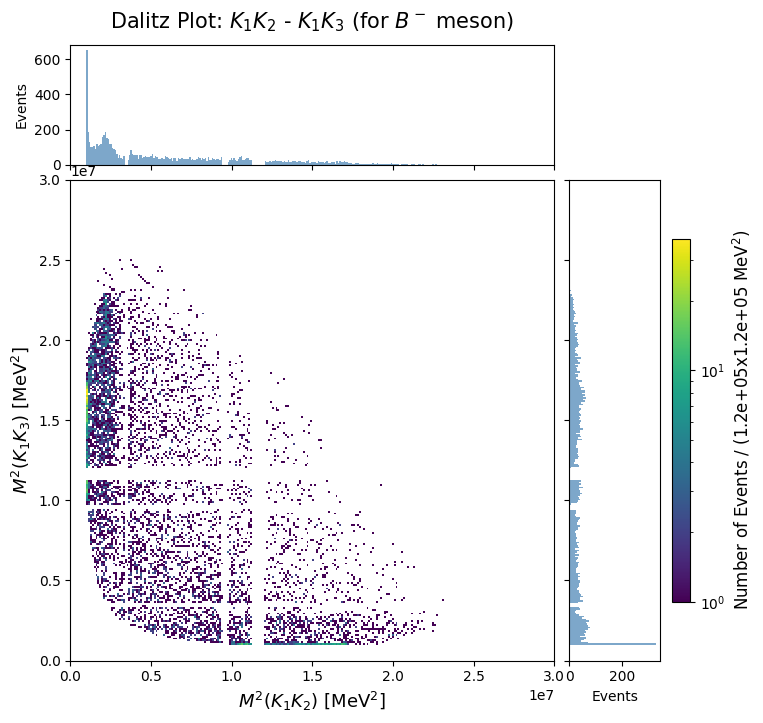

In [72]:
data_charge_split = lf.split_by_charge(data_window, col=data.columns)
for charge, data_split in data_charge_split.items():
    print("B charge: ", charge)
    interesting_mass = {}
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    interesting_mass['12'] = all_mass['12']
    interesting_mass['13'] = all_mass['13']

    fig, ax, ax_top, ax_left, *_ = lf.dalitz_plot(cfg, mass=interesting_mass, bins=250, range=[[0,3e7],[0,3e7]], remove_resonances=['D', 'J', 'chi'],
                                                    add_title=r' (for $B^+$ meson)' if charge=='pos' else r' (for $B^-$ meson)')

**Asymmetry without Resonances**


=== veto 'D': 18744 candidates ===  valid: True
A_CP = -0.0493 ± 0.0087   (relative error 17.6%, Hesse significance 5.68 sigma)
Chi2:         431.73
NDOF:         388
Chi2 / NDOF:  1.113
p-value:      0.0620
H0: A_CP = 0  ->  t = 32.30,  p-value = 1.32e-08  (Z = sqrt(t) = 5.68 sigma)

=== veto 'all': 16367 candidates ===  valid: True
A_CP = -0.0421 ± 0.0094   (relative error 22.2%, Hesse significance 4.50 sigma)
Chi2:         421.11
NDOF:         388
Chi2 / NDOF:  1.085
p-value:      0.1190
H0: A_CP = 0  ->  t = 20.31,  p-value = 6.60e-06  (Z = sqrt(t) = 4.51 sigma)


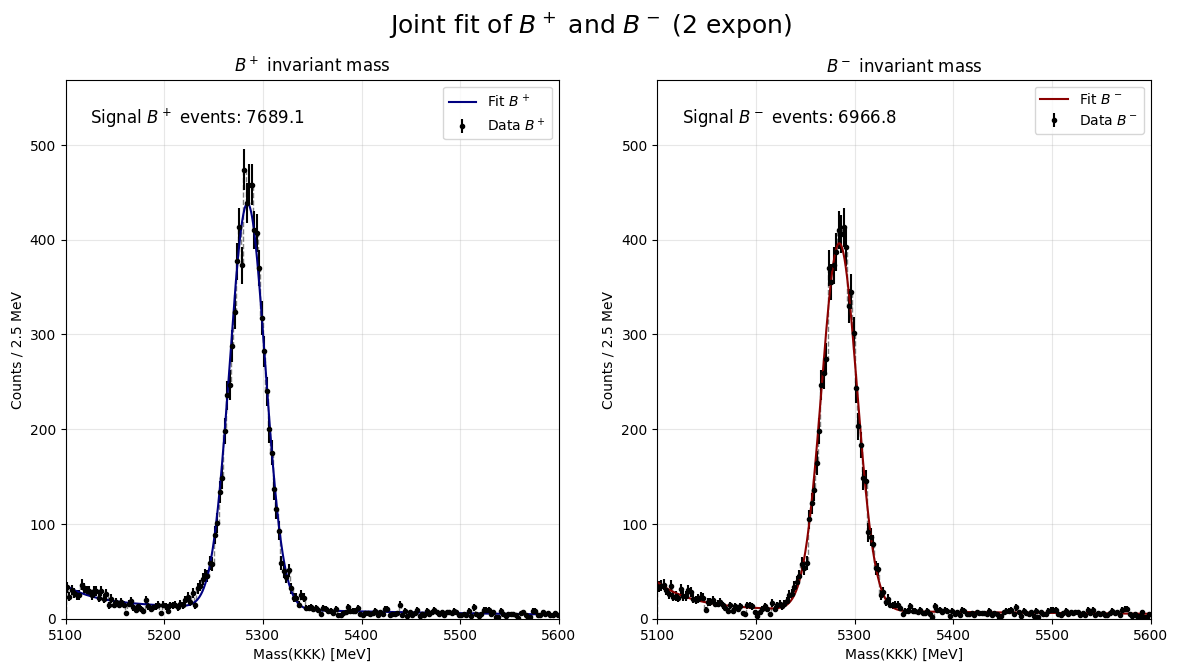

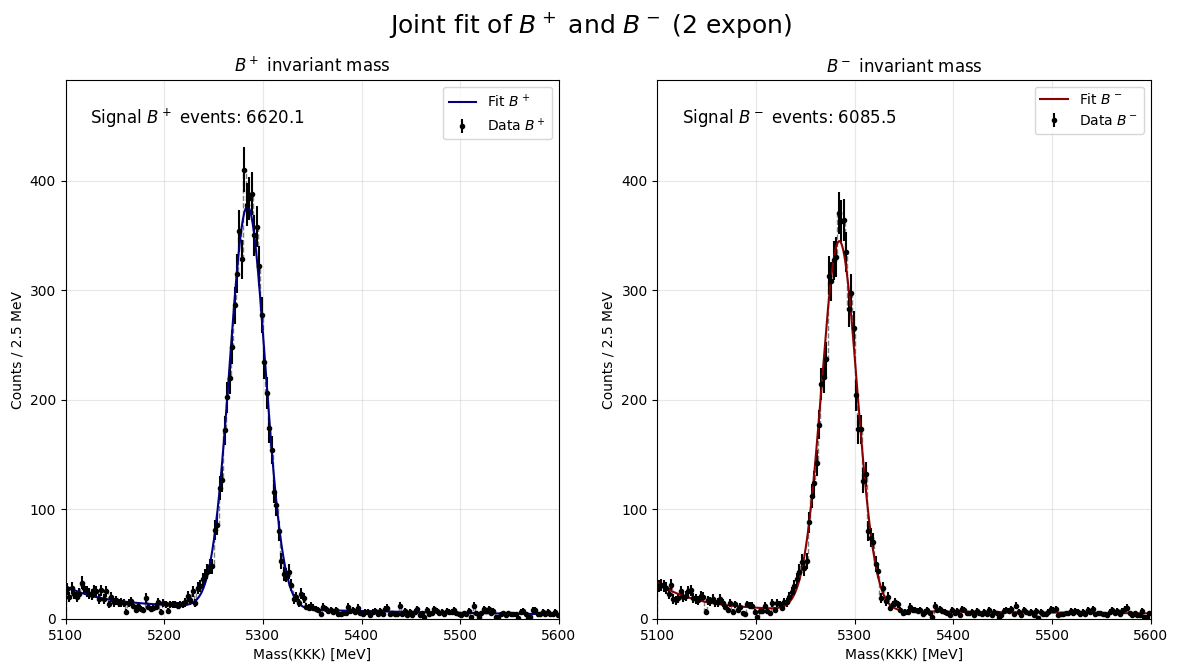

In [73]:
# charm veto in the two versions used in the report: 'D' (D0 only) and 'all' (D0 + J/psi + chi_c0).
# Control counts in the window [5100, 5600]: 18744 and 16367 candidates.
best_without_resonances = {}
for mode in ("D", "all"):
    data_without_resonances = lf.remove_charm_resonances(cfg, data_window, mode)
    samples_without_resonances = lf.split_by_charge(data_without_resonances, col='B_Mass')
    m = lf.fit_joint(samples_without_resonances, cfg, n_exp=2, minos=True)
    best_without_resonances[mode] = m
    print(f"\n=== veto '{mode}': {len(data_without_resonances)} candidates ===  valid: {m.valid}")
    lf.print_asymmetry(m)
    print(lf.gof_joint(m, samples_without_resonances, cfg, n_exp=2))
    lf.plot_joint_fit(m, samples_without_resonances, cfg, n_exp=2)
    t, p, _ = lf.wilks_test(m, {"A_CP": 0.0})
    print(f"H0: A_CP = 0  ->  t = {t:.2f},  p-value = {p:.2e}  (Z = sqrt(t) = {np.sqrt(t):.2f} sigma)")

**Asymmetry Dalitz Plot**

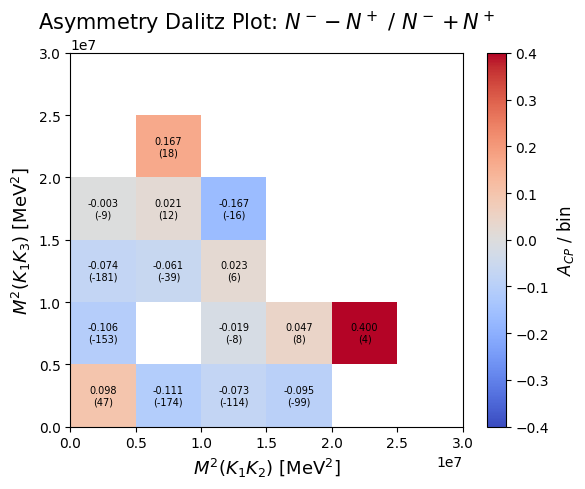

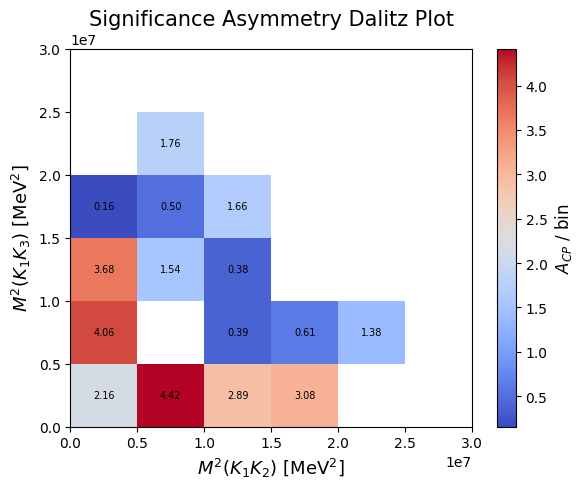

In [74]:
bins_histo_asymm=6

histo = {}
for charge, data_split in data_charge_split.items():
    # print("B charge: ", charge)
    interesting_mass = {}
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    interesting_mass['12'] = all_mass['12']
    interesting_mass['13'] = all_mass['13']

    fig, ax, ax_top, ax_left, *histo[charge] = lf.dalitz_plot(cfg, mass=interesting_mass, bins=bins_histo_asymm, range=[[0,3e7],[0,3e7]], remove_resonances=['D', 'J', 'chi'],
                                                    add_title=r' (for $B^+$ meson)' if charge=='pos' else r' (for $B^-$ meson)')
    plt.close()


x_centers = np.array((histo['neg'][1][:-1] + histo['neg'][1][1:]) / 2)
y_centers = np.array((histo['neg'][2][:-1] + histo['neg'][2][1:]) / 2)

with np.errstate(divide='ignore', invalid='ignore'):
    histo_diff = histo['neg'][0] - histo['pos'][0]
    histo_A_CP, histo_err_A_CP = lf.raw_asymmetry(histo['pos'][0], histo['neg'][0])
    histo_A_CP = np.nan_to_num(histo_A_CP, nan=0.0)
    histo_err_A_CP = np.nan_to_num(histo_err_A_CP, nan=0.0)

histo_A_CP_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, histo_A_CP)
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.pcolormesh(
    histo['pos'][1], histo['pos'][2], histo_A_CP_masked.T,
    cmap='coolwarm', 
    norm=CenteredNorm(vcenter=0)
)
for i in np.arange(len(x_centers)):
    for j in np.arange(len(y_centers)):
        val1 = histo_diff[i, j]
        val2 = histo_A_CP[i, j]
        err_val2 = histo_err_A_CP[i, j]
        
        if abs(val1) > 1:
            ax.text(
                x_centers[i],
                y_centers[j],
                f"{val2:.3f}\n({int(val1)})",
                ha='center',
                va='center',
                fontsize=7,
                color='black'
            )

ax.set_xlabel(r"$M^2(K_1K_2)$ [MeV$^2$]", fontsize=13)
ax.set_ylabel(r"$M^2(K_1K_3)$ [MeV$^2$]", fontsize=13)
ax.set_title(r"Asymmetry Dalitz Plot: $N^- - N^+$ / $N^- + N^+$", fontsize=15)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$A_{CP}$ / bin", fontsize=12)
fig.tight_layout()
plt.show()

# -----------------------------------------------------------------------------------------------------------

histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.pcolormesh(
    histo['pos'][1], histo['pos'][2], histo_significance_masked.T, 
    cmap='coolwarm', 
    # norm=CenteredNorm(vcenter=0)
)

for i in np.arange(len(x_centers)):
    for j in np.arange(len(y_centers)):
        val1 = histo_diff[i, j]
        val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])
        if abs(val1) > 1:
            ax.text(
                x_centers[i],
                y_centers[j],
                f"{val2:.2f}",
                ha='center',
                va='center',
                fontsize=7,
                color='black'
            )

ax.set_xlabel(r"$M^2(K_1K_2)$ [MeV$^2$]", fontsize=13)
ax.set_ylabel(r"$M^2(K_1K_3)$ [MeV$^2$]", fontsize=13)
ax.set_title(r"Significance Asymmetry Dalitz Plot", fontsize=15)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$A_{CP}$ / bin", fontsize=12)
fig.tight_layout()
plt.show()

#### Selecting Dalitz Plot Regions for A_CP Measurement

In [75]:
# two notes on this selection:
# 1) the region is chosen by looking at the asymmetry map: the Wilks p-value computed afterwards does not account
#    for this choice (look-elsewhere), so it is exploratory (the a-priori region of the published analysis is used
#    in the report);
# 2) it uses UNORDERED m12^2 and m13^2: H2 and H3 are interchangeable, so a non-symmetric region selects events by an
#    arbitrary label. The report uses m^2_lo = min(m12^2, m13^2), m^2_hi = max(...).
# The significance of the bins of the maps above is computed with respect to zero; the report compares with the
# global asymmetry, (A_i - A_glob)/sigma_i.
cut_dalitz_mass = {}
for charge, data_split in data_charge_split.items():
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    mask_dalitz_plot = (all_mass['12']**2 <= 1.0e7) & (all_mass['12']**2 >= 0.5e7) & (all_mass['13']**2 <= 0.5e7) & (all_mass['13']**2 >= 0.0e7)
    cut_dalitz_mass[charge] = data_split[mask_dalitz_plot]

events in fit window [5100.0, 5600.0] MeV: 1878
  B+ : 1040   B- : 838  -->  raw A_CP = -0.107561 ± 0.022942
  magnet down: 1096   magnet up: 782


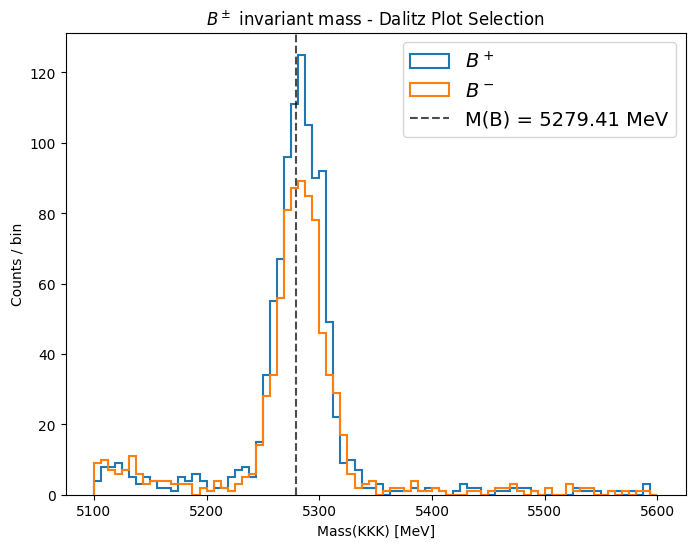

In [76]:
lf.plot_mass_by_charge(pd.concat([cut_dalitz_mass['pos'], cut_dalitz_mass['neg']], ignore_index=True), cfg, bins=80, bin_range=cfg.fit_window,
                       title=r"$B^\pm$ invariant mass - Dalitz Plot Selection")
lf.print_event_summary(pd.concat([cut_dalitz_mass['pos'], cut_dalitz_mass['neg']], ignore_index=True), cfg)

In [77]:
joint_cut_dalitz_mass = {n: lf.fit_joint({'pos': cut_dalitz_mass['pos']['B_Mass'], 'neg': cut_dalitz_mass['neg']['B_Mass']}, cfg, n_exp=n, minos=True) for n in (2, 1)}
display(joint_cut_dalitz_mass[1])

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -3327                      │             Nfcn = 1064              │
│ EDM = 5.65e-05 (Goal: 0.0002)    │            time = 1.1 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name      │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼───────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig     │  1.52e3   │  0.04e3   │  -0.04e3   │   0.04e3   │    0    │         │       │
│ 1 │ A_CP      │  -0.133   │   0.026   │   -0.026   │   0.026    │   -1    │    1    │       │
│ 2 │ mu        │ 5.2843e3  │ 0.0005e3  │ -0.0005e3  │  0.0005e3  │  5200   │  5350   │       │
│ 3 │ sigma     │   18.1    │    0.4    │    -0.4    │    0.4     │    1    │   100   │       │
│ 4 │ N_bkg_pos │    180    │    15     │    -15     │     16     │    0    │         │       │
│ 5 │ lam1_pos  │  4.8e-3   │  0.6e-3   │  -0.6e-3   │   0.6e-3   │  1e-06  │    1    │       │
│ 6 │ N_bkg_neg │    180    │    15     │    -15     │     16     │    0    │         │       │
│ 7 │ lam1_neg  │  5.1e-3   │  0.6e-3   │  -0.6e-3   │   0.6e-3   │  1e-06  │    1    │       │
└───┴───────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         N_sig         │         A_CP          │          mu           │         sigma         │       N_bkg_pos       │       lam1_pos        │       N_bkg_neg       │       lam1_neg        │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │    -40    │    40     │  -0.026   │   0.026   │   -0.5    │    0.5    │   -0.4    │    0.4    │    -15    │    16     │  -0.6e-3  │  0.6e-3   │    -15    │    16     │  -0.6e-3  │  0.6e-3   │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ Max FCN  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ New Min  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
└──────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┘
┌───────────┬──────────────────────────────────────────────────────────────────────────────

In [78]:
# region chosen by looking at the asymmetry map: EXPLORATORY result (look-elsewhere not included).
best_cut_dalitz_mass = joint_cut_dalitz_mass[2]
POIS = ["A_CP", "mu"]                                        # parameters of interest
nuisance = [p for p in best_cut_dalitz_mass.parameters if p not in POIS]     # everything else is profiled

t, p, _ = lf.wilks_test(best_cut_dalitz_mass, {"A_CP": 0.0})                 # H0: no CP violation
# significance Z = sqrt(t) (likelihood ratio, one parameter), as in the report
print(f"H0: A_CP = 0  ->  t = {t:.2f},  p-value = {p:.2e}  (Z = sqrt(t) = {np.sqrt(t):.2f} sigma)")

H0: A_CP = 0  ->  t = 22.93,  p-value = 1.68e-06  (Z = sqrt(t) = 4.79 sigma)
